# UNSW-NB15 Experiment 1 v2 — 00C PRE-02 Error-Decomposition Diagnostic

**Purpose.** This notebook is a diagnostic continuation of the failed 00B benign-score exchangeability smoke gate. It does **not** authorize formal Notebook 01 and does **not** use final-test outcomes or attack-performance metrics.

It reuses the exact 00B smoke AE checkpoint and frozen corrected PRE-02 representation to answer, in order:

1. Which transformed feature block drives the calibration-vs-development-benign reconstruction-error shift: numerical, `proto`, `state`, or `service`?
2. If the numerical block is the leading contributor, do a small number of standardized numerical features show extreme development-benign values relative to the benign-weight-training fitted `StandardScaler`?
3. Verify on a deterministic sample that PRE-02 numerical transformation agrees with the persisted imputer/scaler, so a schema/order/scaler application defect is not silently confused with genuine distribution shift.

**Decision discipline.** This is an integrity diagnostic, not model selection. MCC, recall, precision, F1, ROC-AUC, PR-AUC, attack-family performance, and final-test outcomes are not computed. The formal AE search remains blocked until the diagnosed cause is corrected and a new 00B-style benign smoke gate passes.


# Experiment 1 v2 — 00C PRE-02 Error-Decomposition Diagnostic

**Dataset:** `UNSW-NB15`  
**Scientific scope:** benign-only diagnosis of the failed 00B exchangeability smoke gate using the frozen corrected PRE-02 representation and the exact persisted smoke AE checkpoint.  
**Upstream authority:** PRE-00 → corrected PRE-01 → corrected PRE-02 → failed 00B smoke gate. This notebook consumes frozen artifacts and does not rebuild preprocessing, partitions, feature policy, taxonomy, or corruption groups.

This notebook is designed for Google Colab and is independently executable after corrected PRE-02 and the failed 00B smoke run exist.


## Corrected UNSW-NB15 source-stratified branch

This notebook belongs to corrected branch `v2_source_stratified_20260918`. It is bound exclusively to PRE-02 output `preprocessing_representation_s12_s14_v3_source_stratified_20260918` and does not reuse scientific runs from the superseded source-imbalanced UNSW branch.


## Numeric additivity patch (v2.0.2)

The prior 00C diagnostic could stop falsely because total MSE and block sums were accumulated through different float32 reduction orders. This patched version leaves the trained smoke model unchanged, validates that the four blocks exactly partition the frozen transformed feature space, and performs diagnostic residual aggregation in float64 from the same per-batch residual array. No scientific model, partition, preprocessing, threshold, or score definition is changed.


## Scientific stage boundary

Weights may be updated only from `benign_weight_train`. `benign_early_stop` may influence early stopping / best-checkpoint selection only. `benign_threshold_calibration` may influence threshold estimation only. Development observations may influence configuration selection or diagnostics but never weight/preprocessing/threshold fitting.
**Final-test outcomes remain sealed in this notebook.**

Attack-family labels are diagnostic metadata only. They are never network inputs, loss targets, threshold inputs, or model-selection criteria.


In [1]:
# ============================================================
# 1. EDITABLE CONFIGURATION
# ============================================================
from pathlib import Path

DATASET_NAME = 'UNSW-NB15'
DATASET_FOLDER = 'UNSW-NB15'
DATASET_PREFIX = 'UNSWNB15'
PROTOCOL_VERSION = "Experiment_1_v2"
NOTEBOOK_STAGE_NUMBER = 1
NOTEBOOK_STAGE = "00C_PRE02_error_decomposition_diagnostic"
NOTEBOOK_VERSION = '2.0.2-source-stratified-diagnostic-additivity-fix'
CODE_VERSION = 'experiment1_v2_model_core_2.0.2_source_stratified_diagnostic_additivity_fix'
PROJECT_FOLDER_NAME = "EXPERIMENT1_V2"
MODEL_BRANCH_VERSION = 'v2_source_stratified_20260918'
PRE02_BRANCH_SUBDIR = 'preprocessing_representation_s12_s14_v3_source_stratified_20260918'

# Optional explicit overrides. Leave None for conservative discovery.
PROJECT_ROOT_OVERRIDE = None
PRE02_ROOT_OVERRIDE = None
GLOBAL_DIR_OVERRIDE = None
STAGE_ROOT_OVERRIDES = {}  # e.g. {"notebook03_confirmation": "/content/..."}

PRIMARY_DRIVE_MOUNTPOINT = Path("/content/drive")
FALLBACK_DRIVE_MOUNTPOINT_BASE = Path("/content/exp1v2_google_drive")

# Formal is the authoritative experiment. Smoke outputs are kept separate.
RUN_MODE = "formal"  # allowed: "formal", "smoke"
SMOKE_UNIQUE_COMPLETED = 2
MAX_SEARCH_ATTEMPTS = 250

print("Dataset:", DATASET_NAME)
print("Stage:", NOTEBOOK_STAGE)
print("Notebook version:", NOTEBOOK_VERSION)


Dataset: UNSW-NB15
Stage: 00C_PRE02_error_decomposition_diagnostic
Notebook version: 2.0.2-source-stratified-diagnostic-additivity-fix


In [2]:
# ============================================================
# 2. RUNTIME DEPENDENCIES, IMPORTS, ENVIRONMENT
# ============================================================
import sys, subprocess, importlib.util

_REQUIRED = {
    "optuna": "optuna>=3.6,<5",
    "pyarrow": "pyarrow>=14",
    "sklearn": "scikit-learn>=1.3",
    "scipy": "scipy>=1.10",
    "matplotlib": "matplotlib>=3.7",
}
for module_name, pip_spec in _REQUIRED.items():
    if importlib.util.find_spec(module_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_spec])

if importlib.util.find_spec("torch") is None:
    raise RuntimeError("PyTorch is required. Use a standard Google Colab runtime with PyTorch installed.")

import os, gc, math, json, time, random, hashlib, platform, shutil, traceback, inspect
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import sklearn
from sklearn.metrics import (
    matthews_corrcoef, recall_score, f1_score, precision_score,
    balanced_accuracy_score, precision_recall_curve, auc,
    average_precision_score, roc_auc_score, roc_curve,
)
import scipy
from scipy.stats import binomtest
import matplotlib.pyplot as plt
import joblib
import optuna
from optuna.trial import TrialState
import torch
from torch import nn

EXECUTION_UTC = datetime.now(timezone.utc).isoformat()
ENVIRONMENT_INFO = {
    "python": sys.version,
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pyarrow": pa.__version__,
    "scikit_learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "matplotlib": __import__("matplotlib").__version__,
    "optuna": optuna.__version__,
    "torch": torch.__version__,
    "cuda_available": bool(torch.cuda.is_available()),
    "cuda_version": torch.version.cuda,
    "execution_utc": EXECUTION_UTC,
}
display(pd.DataFrame([ENVIRONMENT_INFO]).T.rename(columns={0: "value"}).head(30))


,value
python,"3.13.15 (main, Aug 6 2026, 11:06:22) [GCC 13...."
platform,Linux-6.6.122+-x86_64-with-glibc2.39
numpy,2.1.3
pandas,2.2.3
pyarrow,23.0.1
scikit_learn,1.6.1
scipy,1.16.3
matplotlib,3.10.0
optuna,4.9.0
torch,2.11.0+cu128


In [3]:
# ============================================================
# 3. VERIFIED GOOGLE DRIVE / PROJECT BINDING
# ============================================================
def _find_mydrive(mountpoint):
    mountpoint = Path(mountpoint)
    for name in ["MyDrive", "My Drive"]:
        p = mountpoint / name
        if p.exists() and p.is_dir():
            return p
    return None


def _find_project(mydrive, project_name):
    if mydrive is None:
        return None
    direct = Path(mydrive) / project_name
    if direct.exists() and direct.is_dir():
        return direct.resolve()
    matches = []
    for dirpath, dirnames, _ in os.walk(str(mydrive), topdown=True, followlinks=True):
        dirnames[:] = [d for d in dirnames if d not in {".Trash", ".trash", "__pycache__", ".ipynb_checkpoints"}]
        if project_name in dirnames:
            matches.append((Path(dirpath) / project_name).resolve())
    matches = list(dict.fromkeys(map(str, matches)))
    if len(matches) == 1:
        return Path(matches[0])
    if len(matches) > 1:
        raise RuntimeError(f"Multiple {project_name!r} project roots found: {matches}. Set PROJECT_ROOT_OVERRIDE explicitly.")
    return None


def _fresh_mountpoint(base):
    base = Path(base)
    for i in range(20):
        candidate = base if i == 0 else Path(f"{base}_{i}")
        if not candidate.exists() or (candidate.is_dir() and not any(candidate.iterdir())):
            return candidate
    raise RuntimeError("No fresh alternate Google Drive mountpoint is available under /content.")


try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

if PROJECT_ROOT_OVERRIDE is not None:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    if not PROJECT_ROOT.exists():
        raise FileNotFoundError(f"PROJECT_ROOT_OVERRIDE does not exist: {PROJECT_ROOT}")
    DRIVE_SEARCH_ROOT = PROJECT_ROOT.parent.parent
else:
    primary_mydrive = _find_mydrive(PRIMARY_DRIVE_MOUNTPOINT)
    primary_project = _find_project(primary_mydrive, PROJECT_FOLDER_NAME)
    if primary_project is not None:
        PROJECT_ROOT = primary_project
        DRIVE_SEARCH_ROOT = PRIMARY_DRIVE_MOUNTPOINT.resolve()
    else:
        if not IN_COLAB:
            raise RuntimeError("Verified Google Drive project is unavailable. Set PROJECT_ROOT_OVERRIDE explicitly.")
        alt = _fresh_mountpoint(FALLBACK_DRIVE_MOUNTPOINT_BASE)
        print("Mounting Google Drive at verified alternate mountpoint:", alt)
        drive.mount(str(alt), force_remount=False)
        alt_mydrive = _find_mydrive(alt)
        PROJECT_ROOT = _find_project(alt_mydrive, PROJECT_FOLDER_NAME)
        if PROJECT_ROOT is None:
            raise FileNotFoundError(f"Mounted Drive does not contain {PROJECT_FOLDER_NAME!r}. Set PROJECT_ROOT_OVERRIDE if renamed.")
        DRIVE_SEARCH_ROOT = alt.resolve()

DATASET_ROOT = PROJECT_ROOT / "DATASETS" / DATASET_FOLDER
if not DATASET_ROOT.exists():
    raise FileNotFoundError(f"Dataset root is missing: {DATASET_ROOT}")

GLOBAL_DIR = Path(GLOBAL_DIR_OVERRIDE).resolve() if GLOBAL_DIR_OVERRIDE else PROJECT_ROOT / "global"
MODELLING_ROOT = DATASET_ROOT / "modelling"
MODELLING_ROOT.mkdir(parents=True, exist_ok=True)
GLOBAL_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATASET_ROOT:", DATASET_ROOT)
print("GLOBAL_DIR:", GLOBAL_DIR)
print("MODELLING_ROOT:", MODELLING_ROOT)


Mounting Google Drive at verified alternate mountpoint: /content/exp1v2_google_drive
Mounted at /content/exp1v2_google_drive
PROJECT_ROOT: /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2
DATASET_ROOT: /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15
GLOBAL_DIR: /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/global
MODELLING_ROOT: /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling


In [4]:
# ============================================================
# 4. HASHING, IMMUTABLE JSON, CONTRACT, AND STAGE UTILITIES
# ============================================================
ALLOWED_PASS_STATUSES = {"PASS", "PASS_WITH_NONBLOCKING_WARNINGS"}


def hard_fail(message):
    print("EXPERIMENT 1 v2 MODEL-STAGE INTEGRITY: FAIL")
    print("Next authorized action: NONE until the blocking issue is corrected/versioned.")
    raise RuntimeError(str(message))


def require(condition, message):
    if not bool(condition):
        hard_fail(message)


def canonical_json_bytes(obj):
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False, allow_nan=False).encode("utf-8")


def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()


def sha256_file(path, block_size=16 * 1024 * 1024):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        while True:
            b = f.read(block_size)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def read_json(path):
    with Path(path).open("r", encoding="utf-8") as f:
        return json.load(f)


def atomic_write_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with tmp.open("w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, sort_keys=True, ensure_ascii=False, allow_nan=False)
        f.write("\n")
    os.replace(tmp, path)


def atomic_write_csv(path, df):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)


def atomic_write_parquet(path, df):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    df.to_parquet(tmp, index=False, compression="snappy")
    os.replace(tmp, path)


def substantive_hash(obj, excluded_keys):
    body = {k: v for k, v in obj.items() if k not in set(excluded_keys)}
    return sha256_bytes(canonical_json_bytes(body)), body


def verify_self_hashed_json(path, hash_field, extra_excluded=()):
    obj = read_json(path)
    excluded = {hash_field, "created_at_utc", *extra_excluded}
    computed, _ = substantive_hash(obj, excluded)
    stored = str(obj.get(hash_field, "")).lower()
    require(stored and computed.lower() == stored, f"Self-hash mismatch for {path}: computed={computed}, stored={stored}")
    return obj, computed


def freeze_contract(path, substantive, hash_field="contract_hash"):
    path = Path(path)
    expected_hash = sha256_bytes(canonical_json_bytes(substantive))
    if path.exists():
        obj = read_json(path)
        stored = str(obj.get(hash_field, "")).lower()
        body = {k: v for k, v in obj.items() if k not in {hash_field, "created_at_utc"}}
        require(stored == expected_hash.lower(), f"Existing contract hash mismatch: {path}")
        require(body == substantive, f"Existing contract substantive content differs: {path}")
        return obj, expected_hash
    obj = {**substantive, "created_at_utc": datetime.now(timezone.utc).isoformat(), hash_field: expected_hash}
    atomic_write_json(path, obj)
    return obj, expected_hash


def verify_contract(path, hash_field="contract_hash"):
    path = Path(path)
    require(path.exists(), f"Required global contract is missing: {path}. Run Notebook 01 first for this Experiment 1 v2 project.")
    return verify_self_hashed_json(path, hash_field)


def make_stage_manifest(substantive):
    h = sha256_bytes(canonical_json_bytes(substantive))
    return {**substantive, "created_at_utc": datetime.now(timezone.utc).isoformat(), "stage_manifest_hash": h}


def write_stage_manifest(path, substantive):
    obj = make_stage_manifest(substantive)
    path = Path(path)
    if path.exists():
        old, _ = verify_self_hashed_json(path, "stage_manifest_hash")
        old_body = {k: v for k, v in old.items() if k not in {"created_at_utc", "stage_manifest_hash"}}
        require(old_body == substantive, f"Existing stage manifest conflicts with current execution contract: {path}")
        return old
    atomic_write_json(path, obj)
    return obj


def load_stage_manifest(path):
    obj, _ = verify_self_hashed_json(path, "stage_manifest_hash")
    require(obj.get("final_status") in ALLOWED_PASS_STATUSES, f"Upstream stage is not PASS: {path}")
    require(obj.get("dataset") == DATASET_NAME, f"Stage manifest dataset mismatch: {path}")
    return obj


def dataset_matches(value):
    a = str(value).strip().casefold().replace("_", "-")
    b = DATASET_NAME.casefold().replace("_", "-")
    aliases = {b}
    if DATASET_NAME == "CICIDS2017": aliases |= {"cicids-2017", "cicids2017"}
    else: aliases |= {"unsw-nb15", "unswnb15"}
    return a in aliases


def discover_one(paths, description):
    unique = []
    seen = set()
    for p in paths:
        p = Path(p).resolve()
        if str(p) not in seen:
            unique.append(p); seen.add(str(p))
    require(len(unique) == 1, f"Expected exactly one {description}; found {len(unique)}: {[str(x) for x in unique]}")
    return unique[0]


def resolve_dependency_stage(stage_slug, require_formal=False):
    override = STAGE_ROOT_OVERRIDES.get(stage_slug)
    if override:
        root = Path(override).resolve()
        manifest_path = root / "stage_manifest.json"
        manifest = load_stage_manifest(manifest_path)
        for rel, expected in manifest.get("key_artifact_hashes", {}).items():
            ap = root / rel
            require(ap.exists(), f"Frozen upstream stage artifact is missing: {ap}")
            require(sha256_file(ap) == expected, f"Frozen upstream stage artifact hash mismatch: {ap}")
        return root, manifest
    base = MODELLING_ROOT / stage_slug / MODEL_BRANCH_VERSION
    candidates = []
    if base.exists():
        for p in base.rglob("stage_manifest.json"):
            try:
                obj, _ = verify_self_hashed_json(p, "stage_manifest_hash")
                if obj.get("dataset") != DATASET_NAME or obj.get("final_status") not in ALLOWED_PASS_STATUSES:
                    continue
                if require_formal and obj.get("run_mode") != "formal":
                    continue
                candidates.append(p.parent.resolve())
            except Exception:
                continue
    root = discover_one(candidates, f"valid upstream stage root for {stage_slug}")
    manifest = load_stage_manifest(root / "stage_manifest.json")
    for rel, expected in manifest.get("key_artifact_hashes", {}).items():
        ap = root / rel
        require(ap.exists(), f"Frozen upstream stage artifact is missing: {ap}")
        require(sha256_file(ap) == expected, f"Frozen upstream stage artifact hash mismatch: {ap}")
    return root, manifest


def create_artifact_inventory(root, output_path):
    root = Path(root); output_path = Path(output_path)
    rows = []
    for p in sorted(root.rglob("*")):
        if not p.is_file() or p.resolve() == output_path.resolve() or p.name.endswith(".tmp"):
            continue
        rows.append({
            "relative_path": str(p.relative_to(root)),
            "size_bytes": int(p.stat().st_size),
            "sha256": sha256_file(p),
        })
    atomic_write_csv(output_path, pd.DataFrame(rows))
    return rows


In [5]:
# ============================================================
# 5. DISCOVER / VERIFY PRE-02 AND FREEZE / VERIFY GLOBAL CONTRACTS
# ============================================================
ALLOW_GLOBAL_CONTRACT_CREATION = True


def discover_pre02_root():
    if PRE02_ROOT_OVERRIDE:
        root = Path(PRE02_ROOT_OVERRIDE).resolve()
        report_path = root / "reports" / "preprocessing_integrity_report.json"
        require(report_path.exists(), f"Explicit PRE02 root lacks integrity report: {root}")
        return root
    preferred = DATASET_ROOT / PRE02_BRANCH_SUBDIR
    preferred_report = preferred / "reports" / "preprocessing_integrity_report.json"
    if preferred_report.exists():
        report = read_json(preferred_report)
        require(report.get("final_status") in ALLOWED_PASS_STATUSES, f"Corrected PRE-02 is not PASS: {preferred_report}")
        return preferred.resolve()
    require(False, f"Corrected PRE-02 root is missing: {preferred}. Run the corrected PRE-02 notebook first.")

    candidates = []
    for report_path in DATASET_ROOT.rglob("preprocessing_integrity_report.json"):
        try:
            report = read_json(report_path)
            if not dataset_matches(report.get("dataset")):
                continue
            if report.get("final_status") not in ALLOWED_PASS_STATUSES:
                continue
            root = report_path.parent.parent
            needed = [
                root / "manifests" / "preprocessing_policy_manifest.json",
                root / "manifests" / "transformed_representation_manifest.json",
                root / "manifests" / "corruption_group_manifest.json",
                root / "fitted_preprocessor.joblib",
            ]
            if all(p.exists() for p in needed):
                candidates.append(root.resolve())
        except Exception:
            continue
    return discover_one(candidates, "valid PRE-02 output root")


PRE02_ROOT = discover_pre02_root()
PRE02_INTEGRITY_PATH = PRE02_ROOT / "reports" / "preprocessing_integrity_report.json"
PRE02_INTEGRITY = read_json(PRE02_INTEGRITY_PATH)
require(PRE02_INTEGRITY.get("final_status") in ALLOWED_PASS_STATUSES, "PRE-02 integrity is not PASS/PASS_WITH_NONBLOCKING_WARNINGS.")
require(dataset_matches(PRE02_INTEGRITY.get("dataset")), "PRE-02 dataset mismatch.")

PREPROCESSING_POLICY_PATH = PRE02_ROOT / "manifests" / "preprocessing_policy_manifest.json"
REPRESENTATION_PATH = PRE02_ROOT / "manifests" / "transformed_representation_manifest.json"
CORRUPTION_PATH = PRE02_ROOT / "manifests" / "corruption_group_manifest.json"
FITTED_PREPROCESSOR_PATH = PRE02_ROOT / "fitted_preprocessor.joblib"

PREPROCESSING_POLICY = read_json(PREPROCESSING_POLICY_PATH)
# PRE-02 policy hash excludes operational_storage and timestamp.
policy_body = {k: v for k, v in PREPROCESSING_POLICY.items() if k not in {"preprocessing_policy_hash", "created_at_utc", "operational_storage"}}
PREPROCESSING_POLICY_HASH = sha256_bytes(canonical_json_bytes(policy_body))
require(PREPROCESSING_POLICY_HASH == str(PREPROCESSING_POLICY.get("preprocessing_policy_hash", "")), "PRE-02 preprocessing policy self-hash mismatch.")

REPRESENTATION, REPRESENTATION_HASH = verify_self_hashed_json(REPRESENTATION_PATH, "transformed_representation_manifest_hash")
CORRUPTION, CORRUPTION_HASH = verify_self_hashed_json(CORRUPTION_PATH, "corruption_group_manifest_hash")
FITTED_PREPROCESSOR_HASH = sha256_file(FITTED_PREPROCESSOR_PATH)

require(PREPROCESSING_POLICY_HASH == PRE02_INTEGRITY.get("preprocessing_policy_hash"), "PRE-02 policy hash disagrees with integrity report.")
require(REPRESENTATION_HASH == PRE02_INTEGRITY.get("transformed_representation_manifest_hash"), "PRE-02 representation hash disagrees with integrity report.")
require(CORRUPTION_HASH == PRE02_INTEGRITY.get("corruption_group_manifest_hash"), "PRE-02 corruption hash disagrees with integrity report.")
require(FITTED_PREPROCESSOR_HASH == PRE02_INTEGRITY.get("fitted_preprocessor_hash"), "PRE-02 fitted preprocessor hash disagrees with integrity report.")
require(REPRESENTATION.get("feature_order_hash") == PRE02_INTEGRITY.get("feature_order_hash"), "PRE-02 feature-order hash mismatch.")
require(REPRESENTATION.get("corruption_group_manifest_hash") == CORRUPTION_HASH, "Representation is not bound to the loaded corruption manifest.")
require(REPRESENTATION.get("preprocessing_policy_hash") == PREPROCESSING_POLICY_HASH, "Representation is not bound to the loaded preprocessing policy.")
require(REPRESENTATION.get("fitted_preprocessor_hash") == FITTED_PREPROCESSOR_HASH, "Representation is not bound to the fitted preprocessor.")

PRE00_STATUS = PRE02_INTEGRITY.get("upstream_verification", {}).get("pre00_status")
PRE01_STATUS = PRE02_INTEGRITY.get("upstream_verification", {}).get("pre01_status")
require(PRE00_STATUS in ALLOWED_PASS_STATUSES, f"PRE-00 upstream status is not acceptable: {PRE00_STATUS}")
require(PRE01_STATUS in ALLOWED_PASS_STATUSES, f"PRE-01 upstream status is not acceptable: {PRE01_STATUS}")
UPSTREAM_HASHES = dict(PRE02_INTEGRITY.get("upstream_hashes", {}))

GLOBAL_PROTOCOL_PATH = PROJECT_ROOT / "global" / "experiment1_v2_global_protocol.json"
require(GLOBAL_PROTOCOL_PATH.exists(), f"Global protocol is missing: {GLOBAL_PROTOCOL_PATH}")
GLOBAL_PROTOCOL = read_json(GLOBAL_PROTOCOL_PATH)
_gp_body = dict(GLOBAL_PROTOCOL); _gp_stored = str(_gp_body.pop("canonical_protocol_hash", ""));
GLOBAL_PROTOCOL_HASH = sha256_bytes(canonical_json_bytes(_gp_body))
require(GLOBAL_PROTOCOL_HASH == _gp_stored == str(UPSTREAM_HASHES.get("global_protocol_hash", "")), "Global protocol canonical hash mismatch.")

# ------------------------------------------------------------
# Global Experiment 1 v2 post-PRE-02 contracts
# ------------------------------------------------------------
SEED_SCHEDULE_SUBSTANTIVE = {
    "version": "Experiment1_v2_seed_schedule_v1",
    "protocol_version": PROTOCOL_VERSION,
    "OPTUNA_SAMPLER_SEED": 2026,
    "SEARCH_SEED": 101,
    "CONFIRMATION_SEEDS": [101, 202, 303],
    "ABLATION_SEEDS": [101, 202, 303],
    "THRESHOLD_SENSITIVITY_SEED": 101,
    "SENSITIVITY_SEEDS": [101, 202, 303],
    "FINAL_SEEDS": [101, 202, 303, 404, 505],
}
# Resolve unspecified library-level optimizer/loss/scheduler defaults without inventing them.
# If the global contract already exists, its frozen values take precedence; otherwise
# the current PyTorch defaults are captured prospectively and then frozen.
_existing_model_contract_path = GLOBAL_DIR / "model_search_contract.json"
if _existing_model_contract_path.exists():
    _existing_model_contract = read_json(_existing_model_contract_path)
    _existing_fixed = _existing_model_contract.get("fixed_training", {})
    HUBER_DELTA_EFFECTIVE = float(_existing_fixed["huber_delta"])
    ADAMW_FIXED_DEFAULTS = dict(_existing_fixed["adamw_fixed_defaults"])
    SCHEDULER_FIXED_DEFAULTS = dict(_existing_fixed["reduce_lr_on_plateau_fixed_defaults"])
else:
    _huber_sig = inspect.signature(nn.HuberLoss)
    HUBER_DELTA_EFFECTIVE = float(_huber_sig.parameters["delta"].default)
    _adam_sig = inspect.signature(torch.optim.AdamW)
    ADAMW_FIXED_DEFAULTS = {}
    for _name in ["betas", "eps", "amsgrad", "maximize", "foreach", "capturable", "differentiable", "fused"]:
        if _name in _adam_sig.parameters:
            _value = _adam_sig.parameters[_name].default
            if isinstance(_value, tuple): _value = list(_value)
            ADAMW_FIXED_DEFAULTS[_name] = _value
    _sched_sig = inspect.signature(torch.optim.lr_scheduler.ReduceLROnPlateau)
    SCHEDULER_FIXED_DEFAULTS = {}
    for _name in ["threshold", "threshold_mode", "cooldown", "eps"]:
        if _name in _sched_sig.parameters:
            SCHEDULER_FIXED_DEFAULTS[_name] = _sched_sig.parameters[_name].default

MODEL_SEARCH_CONTRACT_SUBSTANTIVE = {
    "version": "Experiment1_v2_model_search_contract_v1",
    "protocol_version": PROTOCOL_VERSION,
    "framework": "PyTorch",
    "architectures": {
        "A": [32, 16],
        "B": [64, 32],
        "C": [64, 32, 16],
    },
    "latent_fraction_candidates": [0.25, 0.50],
    "learning_rate": {"distribution": "log_uniform", "low": 1e-4, "high": 1e-3},
    "batch_size_candidates": [128, 256, 512],
    "weight_decay_candidates": [0.0, 1e-6, 1e-5, 1e-4],
    "training_loss_candidates": ["MSE", "Huber"],
    "dae_corruption_search": {
        "CICIDS2017": {"numerical_masking": [0.05, 0.10, 0.15], "categorical_masking": "N/A"},
        "UNSW-NB15": {"numerical_masking": [0.05, 0.10, 0.15], "grouped_categorical_masking": [0.02, 0.05, 0.10]},
    },
    "fixed_training": {
        "optimizer": "AdamW", "hidden_activation": "ReLU", "output_activation": "Linear",
        "weight_initialization": "Kaiming_normal", "maximum_epochs": 150,
        "early_stopping_patience": 12, "lr_scheduler": "ReduceLROnPlateau",
        "lr_scheduler_patience": 5, "lr_reduction_factor": 0.5,
        "minimum_learning_rate": 1e-6, "gradient_clip_norm": 1.0,
        "huber_delta": HUBER_DELTA_EFFECTIVE,
        "huber_delta_source": "PyTorch HuberLoss default captured when contract first frozen",
        "adamw_fixed_defaults": ADAMW_FIXED_DEFAULTS,
        "reduce_lr_on_plateau_fixed_defaults": SCHEDULER_FIXED_DEFAULTS,
        "kaiming_normal_details": {"mode": "fan_in", "nonlinearity": "relu", "bias": "zero"},
    },
    "formal_unique_completed_budget_per_model_per_dataset": 20,
    "smoke_outputs_excluded_from_formal": True,
    "duplicates_do_not_count": True,
    "duplicate_trial_optuna_state": "PRUNED with duplicate_detected=true; administrative duplicate state only",
    "model_pruning_enabled": False,
    "failed_interrupted_trials_do_not_count": True,
    "search_shortlist_size": 3,
    "search_stage_ranking": ["development_MCC_desc", "FPR_asc", "PR_AUC_desc", "parameter_count_asc", "training_duration_asc"],
    "confirmation_selection_hierarchy": ["mean_development_MCC_desc", "mean_FPR_asc", "mean_PR_AUC_desc", "MCC_SD_asc", "parameter_count_asc", "mean_training_duration_asc"],
    "family_metrics_used_for_selection": False,
    "reconstruction_score": "per_observation_mean_squared_reconstruction_error",
}
_existing_threshold_contract_path = GLOBAL_DIR / "threshold_contract.json"
if _existing_threshold_contract_path.exists():
    _existing_threshold_contract = read_json(_existing_threshold_contract_path)
    QUANTILE_METHOD_EFFECTIVE = str(_existing_threshold_contract["quantile_method"])
    DECISION_OPERATOR_EFFECTIVE = str(_existing_threshold_contract["decision_operator"])
else:
    _quantile_sig = inspect.signature(np.quantile)
    QUANTILE_METHOD_EFFECTIVE = str(_quantile_sig.parameters["method"].default)
    # Prospectively frozen before any model run; later notebooks consume the global contract.
    DECISION_OPERATOR_EFFECTIVE = ">"

THRESHOLD_CONTRACT_SUBSTANTIVE = {
    "version": "Experiment1_v2_threshold_contract_v1",
    "protocol_version": PROTOCOL_VERSION,
    "calibration_partition": "benign_threshold_calibration",
    "primary_percentile": 99.0,
    "sensitivity_percentiles": [95.0, 97.0, 99.0, 99.5],
    "quantile_implementation": "numpy.quantile",
    "quantile_method": QUANTILE_METHOD_EFFECTIVE,
    "quantile_method_source": "NumPy quantile default captured when contract first frozen",
    "decision_operator": DECISION_OPERATOR_EFFECTIVE,
    "attack_if": "reconstruction_error > threshold" if DECISION_OPERATOR_EFFECTIVE == ">" else ("reconstruction_error " + DECISION_OPERATOR_EFFECTIVE + " threshold"),
}
METRIC_CONTRACT_SUBSTANTIVE = {
    "version": "Experiment1_v2_metric_contract_v1",
    "protocol_version": PROTOCOL_VERSION,
    "positive_class": "attack=1",
    "primary_metrics": ["MCC", "Recall", "F1", "Precision", "PR-AUC", "FPR", "FP_per_1000_benign", "Balanced_Accuracy"],
    "secondary_score_metrics": ["ROC-AUC", "Average_Precision", "TPR_at_1pct_FPR"],
    "PR_AUC": {"implementation": "sklearn.precision_recall_curve + sklearn.metrics.auc(recall, precision)", "distinct_from_average_precision": True},
    "Average_Precision": {"implementation": "sklearn.metrics.average_precision_score"},
    "FP_per_1000_benign": "1000 * FP / N_benign",
    "TPR_at_1pct_FPR": "maximum ROC TPR among points with FPR <= 0.01",
    "accuracy_primary": False,
}
ARTIFACT_CONTRACT_SUBSTANTIVE = {
    "version": "Experiment1_v2_artifact_contract_v1",
    "protocol_version": PROTOCOL_VERSION,
    "per_run_required": [
        "effective_config.json", "run_manifest.json", "checkpoint.pt", "training_history.csv",
        "calibration_scores.parquet", "evaluation_predictions.parquet", "threshold_manifest.json",
        "metrics.json", "environment.json"
    ],
    "observation_level_fields": ["row_id", "y_true", "reconstruction_error", "threshold", "y_pred", "model", "seed", "config_hash", "run_hash", "attack_family"],
    "failed_runs_preserved": True,
    "checkpoint_paths_run_unique": True,
}

CONTRACT_SPECS = {
    "seed_schedule.json": SEED_SCHEDULE_SUBSTANTIVE,
    "model_search_contract.json": MODEL_SEARCH_CONTRACT_SUBSTANTIVE,
    "threshold_contract.json": THRESHOLD_CONTRACT_SUBSTANTIVE,
    "metric_contract.json": METRIC_CONTRACT_SUBSTANTIVE,
    "artifact_contract.json": ARTIFACT_CONTRACT_SUBSTANTIVE,
}

CONTRACTS = {}
CONTRACT_HASHES = {}
for filename, substantive in CONTRACT_SPECS.items():
    path = GLOBAL_DIR / filename
    if ALLOW_GLOBAL_CONTRACT_CREATION:
        obj, h = freeze_contract(path, substantive)
    else:
        obj, h = verify_contract(path)
        body = {k: v for k, v in obj.items() if k not in {"contract_hash", "created_at_utc"}}
        require(body == substantive, f"Global contract differs from this notebook's frozen Experiment 1 v2 specification: {path}")
    CONTRACTS[filename] = obj
    CONTRACT_HASHES[filename] = h

SEED_SCHEDULE = CONTRACTS["seed_schedule.json"]
MODEL_SEARCH_CONTRACT = CONTRACTS["model_search_contract.json"]
THRESHOLD_CONTRACT = CONTRACTS["threshold_contract.json"]
METRIC_CONTRACT = CONTRACTS["metric_contract.json"]
ARTIFACT_CONTRACT = CONTRACTS["artifact_contract.json"]

UPSTREAM_IDENTITY = {
    "master_dataset_sha256": UPSTREAM_HASHES.get("master_dataset_sha256"),
    "partition_manifest_canonical_hash": UPSTREAM_HASHES.get("partition_manifest_canonical_hash"),
    "partition_manifest_file_sha256": UPSTREAM_HASHES.get("partition_manifest_file_sha256"),
    "preprocessing_policy_hash": PREPROCESSING_POLICY_HASH,
    "fitted_preprocessor_hash": FITTED_PREPROCESSOR_HASH,
    "transformed_representation_manifest_hash": REPRESENTATION_HASH,
    "feature_order_hash": REPRESENTATION.get("feature_order_hash"),
    "corruption_group_manifest_hash": CORRUPTION_HASH,
    **{f"contract::{k}": v for k, v in CONTRACT_HASHES.items()},
}

print("PRE-00 status:", PRE00_STATUS)
print("PRE-01 status:", PRE01_STATUS)
print("PRE-02 status:", PRE02_INTEGRITY.get("final_status"))
print("PASS: upstream PRE-00/PRE-01/PRE-02 identities and global model-stage contracts are frozen and consistent.")
display(pd.DataFrame([{"identity": k, "hash": v} for k, v in UPSTREAM_IDENTITY.items()]))


PRE-00 status: PASS_WITH_NONBLOCKING_WARNINGS
PRE-01 status: PASS_WITH_NONBLOCKING_WARNINGS
PRE-02 status: PASS_WITH_NONBLOCKING_WARNINGS
PASS: upstream PRE-00/PRE-01/PRE-02 identities and global model-stage contracts are frozen and consistent.


,identity,hash
0,master_dataset_sha256,f0447e754fa9ed939ed785e2a8a4d47f3719da2d1fb445...
1,partition_manifest_canonical_hash,1e2c145bd7c8c66ef13c91b7ed1340ec86d111d7a1a339...
2,partition_manifest_file_sha256,3114e887aeff514be147d68a9f938d9c889d2c89a21a1c...
3,preprocessing_policy_hash,d85f5caa5dd7f357088cd1321142ea9d6557843c79d0a0...
4,fitted_preprocessor_hash,38e833cb84550b19eec9430ed6c67b6bb1d24e3a2abf13...
5,transformed_representation_manifest_hash,b3c49fa575f1dfc9917aa2c697ac18795fc49095287e2d...
6,feature_order_hash,783c5cfc1a3950b1bbfbf7ccb3bab0675f8db4dbb2ef18...
7,corruption_group_manifest_hash,93d6d286e11b33470bd3c5e6b04e6621c7e3b1ca688dd8...
8,contract::seed_schedule.json,e9c16b79cfb3677ce3bba3d4a56dda32e47c290df76f03...
9,contract::model_search_contract.json,a18e5092776475ff1153b3f7982df3b6f609889fa25039...


In [6]:
# ============================================================
# 6. FROZEN TRANSFORMED-DATA ACCESS / LOCAL CACHE
# ============================================================
ALLOW_FINAL_TEST_OUTCOMES = False
EXPERIMENTAL_PARTITIONS = ["benign_weight_train", "benign_early_stop", "benign_threshold_calibration", "development", "final_test"]
FEATURE_NAMES = list(REPRESENTATION.get("exact_transformed_feature_order", []))
INPUT_DIM = int(REPRESENTATION.get("total_transformed_dimensionality", -1))
TRANSFORMED_DTYPE = str(REPRESENTATION.get("transformed_dtype"))
require(INPUT_DIM > 0 and len(FEATURE_NAMES) == INPUT_DIM, "Frozen transformed representation has invalid dimension/feature order.")
require(TRANSFORMED_DTYPE in {"float32", "float64"}, f"Unsupported frozen transformed dtype: {TRANSFORMED_DTYPE}")
NP_DTYPE = np.dtype(TRANSFORMED_DTYPE)
TORCH_DTYPE = torch.float32 if TRANSFORMED_DTYPE == "float32" else torch.float64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DATASET_NAME == "CICIDS2017":
    require(CORRUPTION.get("categorical_groups") == {}, "CICIDS corruption manifest unexpectedly contains categorical groups.")
    require(list(CORRUPTION.get("numerical_indices", [])) == list(range(INPUT_DIM)), "CICIDS numerical corruption indices do not cover all dimensions.")
else:
    require(set(CORRUPTION.get("categorical_groups", {})) == {"proto", "state", "service"}, "UNSW corruption groups must be exactly proto/state/service.")

LOCAL_CACHE_ROOT = Path("/content/experiment1_v2_model_cache") / DATASET_PREFIX / REPRESENTATION.get("feature_order_hash", "unknown")
LOCAL_CACHE_ROOT.mkdir(parents=True, exist_ok=True)


def _partition_paths(partition):
    require(partition in EXPERIMENTAL_PARTITIONS, f"Unknown partition: {partition}")
    if partition == "final_test" and not ALLOW_FINAL_TEST_OUTCOMES:
        hard_fail(f"Final-test feature/metadata access is forbidden before Notebook 07. Attempted partition={partition}")
    return (
        PRE02_ROOT / "transformed_partitions" / f"{partition}_transformed.parquet",
        PRE02_ROOT / "transformed_partitions" / f"{partition}_transformed_alignment.parquet",
        PRE02_ROOT / "raw_partitions" / f"{partition}_raw_metadata.parquet",
    )


def _partition_manifest_info(partition):
    info = REPRESENTATION.get("per_partition", {}).get(partition)
    require(isinstance(info, dict), f"Representation manifest lacks partition metadata: {partition}")
    return info


def verify_partition_files(partition, verify_model_bytes=True):
    model_path, alignment_path, metadata_path = _partition_paths(partition)
    info = _partition_manifest_info(partition)
    for p in [model_path, alignment_path, metadata_path]:
        require(p.exists(), f"Required PRE-02 artifact is missing: {p}")
    if verify_model_bytes:
        require(sha256_file(model_path) == info.get("transformed_artifact_sha256"), f"Transformed artifact SHA mismatch for {partition}")
    require(sha256_file(alignment_path) == info.get("transformed_alignment_sha256"), f"Alignment artifact SHA mismatch for {partition}")
    require(sha256_file(metadata_path) == info.get("raw_metadata_sha256"), f"Raw metadata SHA mismatch for {partition}")
    pf = pq.ParquetFile(model_path)
    require(pf.schema_arrow.names == FEATURE_NAMES, f"Feature order mismatch for {partition}")
    require(int(pf.metadata.num_rows) == int(info.get("transformed_row_count")), f"Row count mismatch for {partition}")
    return model_path, alignment_path, metadata_path


def ensure_local_matrix(partition):
    model_path, _, _ = verify_partition_files(partition, verify_model_bytes=True)
    info = _partition_manifest_info(partition)
    rows = int(info["transformed_row_count"])
    cache_path = LOCAL_CACHE_ROOT / f"{partition}.npy"
    meta_path = LOCAL_CACHE_ROOT / f"{partition}.cache.json"
    expected_meta = {
        "source_sha256": info["transformed_artifact_sha256"],
        "rows": rows,
        "columns": INPUT_DIM,
        "dtype": TRANSFORMED_DTYPE,
        "feature_order_hash": REPRESENTATION["feature_order_hash"],
    }
    if cache_path.exists() and meta_path.exists():
        try:
            observed = read_json(meta_path)
            mm = np.load(cache_path, mmap_mode="r")
            if observed == expected_meta and mm.shape == (rows, INPUT_DIM) and str(mm.dtype) == TRANSFORMED_DTYPE:
                return mm
        except Exception:
            pass
        cache_path.unlink(missing_ok=True); meta_path.unlink(missing_ok=True)
    mm = np.lib.format.open_memmap(cache_path, mode="w+", dtype=NP_DTYPE, shape=(rows, INPUT_DIM))
    pf = pq.ParquetFile(model_path)
    offset = 0
    for batch in pf.iter_batches(batch_size=50_000, columns=FEATURE_NAMES):
        arr = batch.to_pandas().to_numpy(dtype=NP_DTYPE, copy=False)
        require(np.isfinite(arr).all(), f"Non-finite value found while caching {partition}")
        mm[offset:offset+len(arr)] = arr
        offset += len(arr)
    require(offset == rows, f"Local cache row count mismatch for {partition}")
    mm.flush(); del mm
    atomic_write_json(meta_path, expected_meta)
    return np.load(cache_path, mmap_mode="r")


def load_partition_metadata(partition):
    _, alignment_path, metadata_path = verify_partition_files(partition, verify_model_bytes=False)
    alignment = pd.read_parquet(alignment_path)
    metadata = pd.read_parquet(metadata_path)
    require(len(alignment) == len(metadata), f"Metadata/alignment row count mismatch for {partition}")
    require(alignment["row_id"].astype(str).reset_index(drop=True).equals(metadata["row_id"].astype(str).reset_index(drop=True)), f"Metadata/alignment row_id mismatch for {partition}")
    require((alignment["partition"].astype(str) == partition).all(), f"Alignment partition label mismatch for {partition}")
    require((metadata["partition"].astype(str) == partition).all(), f"Metadata partition label mismatch for {partition}")
    require("binary_label" in metadata.columns, f"binary_label missing from metadata for {partition}")
    y = pd.to_numeric(metadata["binary_label"], errors="raise").astype(int)
    require(set(y.unique()).issubset({0,1}), f"Unexpected binary labels in {partition}: {sorted(y.unique())}")
    metadata = metadata.copy(); metadata["binary_label"] = y
    return metadata.reset_index(drop=True)


def verify_role_contracts(include_final=False):
    rows = []
    for p in ["benign_weight_train", "benign_early_stop", "benign_threshold_calibration", "development"] + (["final_test"] if include_final else []):
        meta = load_partition_metadata(p)
        attacks = int(meta["binary_label"].sum())
        if p in {"benign_weight_train", "benign_early_stop", "benign_threshold_calibration"}:
            require(attacks == 0, f"{p} is not benign-only.")
        if p in {"development", "final_test"}:
            require(meta["binary_label"].nunique() == 2, f"{p} must contain benign and attack observations.")
        rows.append({"partition": p, "rows": len(meta), "attack_rows": attacks, "benign_rows": len(meta)-attacks})
        del meta; gc.collect()
    display(pd.DataFrame(rows))
    return rows

print("Frozen input dimension:", INPUT_DIM)
print("Frozen transformed dtype:", TRANSFORMED_DTYPE)
print("Model device:", DEVICE)


Frozen input dimension: 78
Frozen transformed dtype: float32
Model device: cuda


In [7]:
# ============================================================
# 7. MODEL, TRAINING, CORRUPTION, THRESHOLD, AND METRIC UTILITIES
# ============================================================
ARCHITECTURES = MODEL_SEARCH_CONTRACT["architectures"]
FIXED_TRAINING = MODEL_SEARCH_CONTRACT["fixed_training"]
_adam_params = set(inspect.signature(torch.optim.AdamW).parameters)
for _k in FIXED_TRAINING.get("adamw_fixed_defaults", {}):
    require(_k in _adam_params, f"Frozen AdamW argument {_k!r} is unsupported by this PyTorch runtime; do not silently substitute defaults.")
_sched_params = set(inspect.signature(torch.optim.lr_scheduler.ReduceLROnPlateau).parameters)
for _k in FIXED_TRAINING.get("reduce_lr_on_plateau_fixed_defaults", {}):
    require(_k in _sched_params, f"Frozen scheduler argument {_k!r} is unsupported by this PyTorch runtime; do not silently substitute defaults.")


def set_global_seed(seed):
    seed = int(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Deterministic algorithms are requested where available; some CUDA operations
    # may still depend on runtime/library support and this limitation is recorded.
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def latent_dim_for(architecture, latent_fraction):
    hidden = ARCHITECTURES[str(architecture)]
    final_width = int(hidden[-1])
    z = max(1, int(round(final_width * float(latent_fraction))))
    require(z < INPUT_DIM, f"Latent dimension must be undercomplete: z={z}, p={INPUT_DIM}")
    return z


class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_widths, latent_dim):
        super().__init__()
        enc = []
        prev = int(input_dim)
        for width in hidden_widths:
            layer = nn.Linear(prev, int(width)); nn.init.kaiming_normal_(layer.weight, mode="fan_in", nonlinearity="relu"); nn.init.zeros_(layer.bias)
            enc += [layer, nn.ReLU()]; prev = int(width)
        latent = nn.Linear(prev, int(latent_dim)); nn.init.kaiming_normal_(latent.weight, mode="fan_in", nonlinearity="relu"); nn.init.zeros_(latent.bias)
        enc += [latent]
        self.encoder = nn.Sequential(*enc)

        dec = []
        prev = int(latent_dim)
        for width in reversed(hidden_widths):
            layer = nn.Linear(prev, int(width)); nn.init.kaiming_normal_(layer.weight, mode="fan_in", nonlinearity="relu"); nn.init.zeros_(layer.bias)
            dec += [layer, nn.ReLU()]; prev = int(width)
        out = nn.Linear(prev, int(input_dim)); nn.init.kaiming_normal_(out.weight, mode="fan_in", nonlinearity="relu"); nn.init.zeros_(out.bias)
        dec += [out]
        self.decoder = nn.Sequential(*dec)

    def forward(self, x):
        return self.decoder(self.encoder(x))


def build_model(config):
    return Autoencoder(INPUT_DIM, ARCHITECTURES[config["architecture"]], int(config["latent_dim"])).to(device=DEVICE, dtype=TORCH_DTYPE)


def parameter_count(model):
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))


def apply_structured_corruption(clean_x, config):
    x = clean_x.clone()
    numerical_p = float(config.get("numerical_masking", 0.0) or 0.0)
    numerical_indices = list(map(int, CORRUPTION.get("numerical_indices", [])))
    if numerical_p > 0 and numerical_indices:
        idx = torch.tensor(numerical_indices, dtype=torch.long, device=x.device)
        mask = torch.rand((x.shape[0], len(numerical_indices)), device=x.device) < numerical_p
        vals = x.index_select(1, idx)
        vals = torch.where(mask, torch.zeros_like(vals), vals)
        x[:, idx] = vals
    cat_p = float(config.get("grouped_categorical_masking", 0.0) or 0.0)
    if cat_p > 0:
        groups = CORRUPTION.get("categorical_groups", {})
        require(bool(groups), "Categorical masking requested but corruption manifest contains no categorical groups.")
        for _, group in groups.items():
            idx = torch.tensor(list(map(int, group)), dtype=torch.long, device=x.device)
            group_mask = (torch.rand((x.shape[0], 1), device=x.device) < cat_p)
            vals = x.index_select(1, idx)
            vals = torch.where(group_mask, torch.zeros_like(vals), vals)
            x[:, idx] = vals
    return x


def training_loss_fn(name):
    if name == "MSE": return nn.MSELoss(reduction="mean")
    if name == "Huber": return nn.HuberLoss(delta=float(FIXED_TRAINING["huber_delta"]), reduction="mean")
    hard_fail(f"Unsupported training loss: {name}")


def iter_sequential_batches(mm, batch_size):
    for start in range(0, len(mm), int(batch_size)):
        arr = np.asarray(mm[start:start+int(batch_size)])
        yield torch.tensor(arr, dtype=TORCH_DTYPE, device=DEVICE)


def clean_validation_loss(model, mm, batch_size, criterion):
    model.eval(); total = 0.0; n = 0
    with torch.no_grad():
        for xb in iter_sequential_batches(mm, batch_size):
            pred = model(xb); loss = criterion(pred, xb)
            total += float(loss.item()) * len(xb); n += len(xb)
    return total / max(n, 1)


def train_model(config, model_type, seed, checkpoint_path):
    set_global_seed(seed)
    train_mm = ensure_local_matrix("benign_weight_train")
    early_mm = ensure_local_matrix("benign_early_stop")
    model = build_model(config)
    pcount = parameter_count(model)
    _adam_kwargs = dict(FIXED_TRAINING.get("adamw_fixed_defaults", {}))
    if "betas" in _adam_kwargs: _adam_kwargs["betas"] = tuple(_adam_kwargs["betas"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=float(config["learning_rate"]), weight_decay=float(config["weight_decay"]), **_adam_kwargs)
    _sched_kwargs = dict(FIXED_TRAINING.get("reduce_lr_on_plateau_fixed_defaults", {}))
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=float(FIXED_TRAINING["lr_reduction_factor"]),
        patience=int(FIXED_TRAINING["lr_scheduler_patience"]), min_lr=float(FIXED_TRAINING["minimum_learning_rate"]), **_sched_kwargs
    )
    criterion = training_loss_fn(config["training_loss"])
    rng = np.random.default_rng(int(seed))
    best_val = float("inf"); best_epoch = -1; stale = 0; history = []
    started = time.perf_counter()
    checkpoint_path = Path(checkpoint_path); checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    for epoch in range(1, int(FIXED_TRAINING["maximum_epochs"]) + 1):
        model.train(); order = rng.permutation(len(train_mm)); total = 0.0; n = 0
        bs = int(config["batch_size"])
        for start in range(0, len(order), bs):
            idx = order[start:start+bs]
            clean = torch.tensor(np.asarray(train_mm[idx]), dtype=TORCH_DTYPE, device=DEVICE)
            inp = apply_structured_corruption(clean, config) if model_type == "DAE" else clean
            optimizer.zero_grad(set_to_none=True)
            pred = model(inp); loss = criterion(pred, clean); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=float(FIXED_TRAINING["gradient_clip_norm"]))
            optimizer.step()
            total += float(loss.item()) * len(clean); n += len(clean)
        train_loss = total / max(n,1)
        val_loss = clean_validation_loss(model, early_mm, bs, criterion)
        scheduler.step(val_loss)
        lr_now = float(optimizer.param_groups[0]["lr"])
        history.append({"epoch": epoch, "training_loss": train_loss, "early_stop_validation_loss": val_loss, "learning_rate": lr_now})
        if val_loss < best_val:
            best_val = val_loss; best_epoch = epoch; stale = 0
            torch.save({
                "state_dict": model.state_dict(), "config": config, "model_type": model_type,
                "seed": int(seed), "best_epoch": int(best_epoch), "best_validation_loss": float(best_val),
                "input_dim": INPUT_DIM, "feature_order_hash": REPRESENTATION["feature_order_hash"],
            }, checkpoint_path)
        else:
            stale += 1
            if stale >= int(FIXED_TRAINING["early_stopping_patience"]):
                break
    duration = float(time.perf_counter() - started)
    require(checkpoint_path.exists(), "Training completed without a best checkpoint.")
    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(ckpt["state_dict"])
    return model, pd.DataFrame(history), int(best_epoch), float(best_val), duration, pcount


def reconstruction_errors(model, mm, batch_size):
    model.eval(); parts = []
    with torch.no_grad():
        for xb in iter_sequential_batches(mm, batch_size):
            pred = model(xb)
            err = torch.mean((xb - pred) ** 2, dim=1)
            parts.append(err.detach().cpu().numpy().astype(np.float64, copy=False))
    return np.concatenate(parts) if parts else np.empty(0, dtype=np.float64)


def quantile_threshold(scores, percentile):
    return float(np.quantile(np.asarray(scores, dtype=np.float64), float(percentile)/100.0, method=THRESHOLD_CONTRACT["quantile_method"]))


def predict_from_threshold(scores, threshold):
    require(THRESHOLD_CONTRACT["decision_operator"] == ">", "This implementation expects the frozen '>' decision operator.")
    return (np.asarray(scores) > float(threshold)).astype(np.int8)


def compute_metrics(y_true, scores, threshold):
    y = np.asarray(y_true, dtype=int); scores = np.asarray(scores, dtype=np.float64)
    pred = predict_from_threshold(scores, threshold)
    require(set(np.unique(y)).issubset({0,1}), "Metrics received non-binary labels.")
    tp = int(np.sum((y==1)&(pred==1))); tn = int(np.sum((y==0)&(pred==0)))
    fp = int(np.sum((y==0)&(pred==1))); fn = int(np.sum((y==1)&(pred==0)))
    n_benign = int(np.sum(y==0))
    fpr = fp / n_benign if n_benign else float("nan")
    precision_curve, recall_curve, _ = precision_recall_curve(y, scores)
    pr_auc = float(auc(recall_curve, precision_curve))
    roc_auc = float(roc_auc_score(y, scores)) if len(np.unique(y)) == 2 else float("nan")
    ap = float(average_precision_score(y, scores)) if len(np.unique(y)) == 2 else float("nan")
    if len(np.unique(y)) == 2:
        fpr_curve, tpr_curve, _ = roc_curve(y, scores)
        eligible = tpr_curve[fpr_curve <= 0.01]
        tpr1 = float(np.max(eligible)) if len(eligible) else 0.0
    else:
        tpr1 = float("nan")
    return {
        "MCC": float(matthews_corrcoef(y, pred)),
        "Recall": float(recall_score(y, pred, zero_division=0)),
        "F1": float(f1_score(y, pred, zero_division=0)),
        "Precision": float(precision_score(y, pred, zero_division=0)),
        "PR-AUC": pr_auc,
        "FPR": float(fpr),
        "FP_per_1000_benign": float(1000.0 * fp / n_benign) if n_benign else float("nan"),
        "Balanced_Accuracy": float(balanced_accuracy_score(y, pred)),
        "ROC-AUC": roc_auc,
        "Average_Precision": ap,
        "TPR_at_1pct_FPR": tpr1,
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
        "threshold": float(threshold),
    }


def family_diagnostics(metadata, predictions):
    df = pd.DataFrame({
        "y_true": metadata["binary_label"].astype(int).to_numpy(),
        "y_pred": np.asarray(predictions, dtype=int),
        "attack_family": metadata.get("attack_family", pd.Series([None]*len(metadata))).astype("string").to_numpy(),
    })
    attacks = df[df["y_true"] == 1].copy()
    require(len(attacks) > 0, "No attacks are available for family diagnostics.")
    require(not pd.isna(attacks["attack_family"]).any(), "Attack-family metadata is missing for one or more attack observations.")
    total_attack = len(attacks); total_tp = int((attacks["y_pred"]==1).sum()); total_fn = int((attacks["y_pred"]==0).sum())
    rows = []
    for family, g in attacks.groupby("attack_family", sort=True, dropna=False):
        support = len(g); tp = int((g["y_pred"]==1).sum()); fn = int((g["y_pred"]==0).sum())
        rows.append({
            "attack_family": str(family), "support": support, "TP": tp, "FN": fn,
            "recall": float(tp/support) if support else float("nan"),
            "attack_share": float(support/total_attack),
            "detected_share": float(tp/total_tp) if total_tp else float("nan"),
            "missed_share": float(fn/total_fn) if total_fn else float("nan"),
        })
    return pd.DataFrame(rows)

print("PASS: model/training/threshold/metric utilities loaded. Anomaly score is fixed per-observation reconstruction MSE.")


PASS: model/training/threshold/metric utilities loaded. Anomaly score is fixed per-observation reconstruction MSE.


In [8]:
# ============================================================
# 8. CONFIG HASH, RUN HASH, RUN PERSISTENCE, EXECUTION
# ============================================================
def normalized_effective_config(model_type, params):
    c = {
        "model_type": str(model_type),
        "architecture": str(params["architecture"]),
        "latent_fraction": float(params["latent_fraction"]),
        "latent_dim": int(params.get("latent_dim", latent_dim_for(params["architecture"], params["latent_fraction"]))),
        "learning_rate": float(params["learning_rate"]),
        "batch_size": int(params["batch_size"]),
        "weight_decay": float(params["weight_decay"]),
        "training_loss": str(params["training_loss"]),
        "optimizer": "AdamW",
        "hidden_activation": "ReLU",
        "output_activation": "Linear",
        "weight_initialization": "Kaiming_normal",
        "maximum_epochs": int(FIXED_TRAINING["maximum_epochs"]),
        "early_stopping_patience": int(FIXED_TRAINING["early_stopping_patience"]),
        "lr_scheduler_patience": int(FIXED_TRAINING["lr_scheduler_patience"]),
        "lr_reduction_factor": float(FIXED_TRAINING["lr_reduction_factor"]),
        "minimum_learning_rate": float(FIXED_TRAINING["minimum_learning_rate"]),
        "gradient_clip_norm": float(FIXED_TRAINING["gradient_clip_norm"]),
        "huber_delta": float(FIXED_TRAINING["huber_delta"]),
        "adamw_fixed_defaults": FIXED_TRAINING.get("adamw_fixed_defaults", {}),
        "reduce_lr_on_plateau_fixed_defaults": FIXED_TRAINING.get("reduce_lr_on_plateau_fixed_defaults", {}),
        "kaiming_normal_details": FIXED_TRAINING.get("kaiming_normal_details", {}),
        "numerical_masking": float(params.get("numerical_masking", 0.0) or 0.0),
        "corruption_group_manifest_hash": CORRUPTION_HASH,
    }
    if DATASET_NAME == "UNSW-NB15" and model_type in {"DAE", "AE_MATCHED"}:
        c["grouped_categorical_masking"] = float(params.get("grouped_categorical_masking", 0.0) or 0.0)
    return c


def config_hash(config):
    return sha256_bytes(canonical_json_bytes(config))


def make_run_hash(stage, model_type, config_h, seed, attempt=1):
    payload = {
        "dataset": DATASET_NAME, "stage": stage, "model_type": model_type,
        "config_hash": config_h, "seed": int(seed),
        "partition_manifest_hash": UPSTREAM_HASHES.get("partition_manifest_canonical_hash"),
        "preprocessing_manifest_hash": PREPROCESSING_POLICY_HASH,
        "transformed_representation_hash": REPRESENTATION_HASH,
        "corruption_group_manifest_hash": CORRUPTION_HASH,
        "code_version": CODE_VERSION, "notebook_version": NOTEBOOK_VERSION,
        "attempt": int(attempt),
    }
    return sha256_bytes(canonical_json_bytes(payload))


def environment_for_run():
    return {**ENVIRONMENT_INFO, "device": str(DEVICE), "torch_dtype": str(TORCH_DTYPE), "code_version": CODE_VERSION, "notebook_version": NOTEBOOK_VERSION}


def _find_existing_complete_run(stage_root, stage, model_type, cfg_hash, seed):
    runs_dir = Path(stage_root) / "runs"
    if not runs_dir.exists(): return None
    for p in runs_dir.glob("*/run_manifest.json"):
        try:
            obj, _ = verify_self_hashed_json(p, "run_manifest_hash")
            if (obj.get("completion_status") == "COMPLETE" and obj.get("stage") == stage and obj.get("model_type") == model_type
                and obj.get("config_hash") == cfg_hash and int(obj.get("seed")) == int(seed)
                and obj.get("upstream_identity") == UPSTREAM_IDENTITY):
                return p.parent, obj
        except Exception:
            continue
    return None


def execute_training_run(stage_root, stage, model_type, params, seed, evaluation_partition="development", allow_reuse=True):
    require(evaluation_partition in {"development", "final_test"}, "Training-run evaluation partition must be development or final_test.")
    if evaluation_partition == "final_test": require(ALLOW_FINAL_TEST_OUTCOMES, "Final-test outcomes are sealed before Notebook 07.")
    config = normalized_effective_config(model_type, params)
    cfg_hash = config_hash(config)
    if allow_reuse:
        found = _find_existing_complete_run(stage_root, stage, model_type, cfg_hash, seed)
        if found is not None:
            run_dir, manifest = found
            print("Reusing validated complete run:", run_dir.name)
            return manifest

    runs_dir = Path(stage_root) / "runs"; runs_dir.mkdir(parents=True, exist_ok=True)
    attempts = []
    for pattern in ["*/run_manifest.json", "*/failure_manifest.json"]:
        for p in runs_dir.glob(pattern):
            try:
                obj = read_json(p)
                if obj.get("stage") == stage and obj.get("model_type") == model_type and obj.get("config_hash") == cfg_hash and int(obj.get("seed", -1)) == int(seed):
                    attempts.append(int(obj.get("attempt", 1)))
            except Exception:
                pass
    attempt = max(attempts, default=0) + 1
    # Hard Colab disconnects can leave orphan run directories without a COMPLETE
    # run_manifest. Preserve them and advance the attempt rather than overwrite.
    while True:
        r_hash = make_run_hash(stage, model_type, cfg_hash, seed, attempt)
        run_dir = runs_dir / r_hash
        if not run_dir.exists():
            break
        print("Detected incomplete/pre-existing run directory; preserving and advancing attempt:", run_dir.name)
        attempt += 1
    run_dir.mkdir(parents=True)
    checkpoint_path = run_dir / "checkpoint.pt"
    atomic_write_json(run_dir / "effective_config.json", {"config_hash": cfg_hash, "effective_config": config})
    atomic_write_json(run_dir / "environment.json", environment_for_run())

    try:
        model, history, best_epoch, best_val, duration, pcount = train_model(config, "DAE" if model_type == "DAE" else "AE", seed, checkpoint_path)
        atomic_write_csv(run_dir / "training_history.csv", history)
        calibration_mm = ensure_local_matrix("benign_threshold_calibration")
        calibration_scores = reconstruction_errors(model, calibration_mm, config["batch_size"])
        calibration_meta = load_partition_metadata("benign_threshold_calibration")
        require(len(calibration_scores) == len(calibration_meta), "Calibration score/metadata length mismatch.")
        cal_df = pd.DataFrame({"row_id": calibration_meta["row_id"].astype(str), "reconstruction_error": calibration_scores})
        atomic_write_parquet(run_dir / "calibration_scores.parquet", cal_df)
        threshold = quantile_threshold(calibration_scores, THRESHOLD_CONTRACT["primary_percentile"])
        threshold_substantive = {
            "percentile": float(THRESHOLD_CONTRACT["primary_percentile"]), "threshold": threshold,
            "calibration_partition": "benign_threshold_calibration",
            "calibration_partition_hash": REPRESENTATION["per_partition"]["benign_threshold_calibration"]["transformed_artifact_sha256"],
            "calibration_observations": int(len(calibration_scores)),
            "quantile_implementation": THRESHOLD_CONTRACT["quantile_implementation"], "quantile_method": THRESHOLD_CONTRACT["quantile_method"],
            "score_definition": MODEL_SEARCH_CONTRACT["reconstruction_score"], "decision_operator": THRESHOLD_CONTRACT["decision_operator"],
        }
        threshold_manifest = {**threshold_substantive, "threshold_manifest_hash": sha256_bytes(canonical_json_bytes(threshold_substantive))}
        atomic_write_json(run_dir / "threshold_manifest.json", threshold_manifest)

        eval_mm = ensure_local_matrix(evaluation_partition)
        eval_scores = reconstruction_errors(model, eval_mm, config["batch_size"])
        eval_meta = load_partition_metadata(evaluation_partition)
        require(len(eval_scores) == len(eval_meta), "Evaluation score/metadata length mismatch.")
        y_true = eval_meta["binary_label"].astype(int).to_numpy()
        metrics = compute_metrics(y_true, eval_scores, threshold)
        preds = predict_from_threshold(eval_scores, threshold)
        out = pd.DataFrame({
            "row_id": eval_meta["row_id"].astype(str), "y_true": y_true,
            "reconstruction_error": eval_scores, "threshold": float(threshold), "y_pred": preds,
            "model": model_type, "seed": int(seed), "config_hash": cfg_hash, "run_hash": r_hash,
            "attack_family": eval_meta.get("attack_family", pd.Series([None]*len(eval_meta))).astype("string"),
        })
        if "feature_fingerprint" in eval_meta.columns:
            out["feature_fingerprint"] = eval_meta["feature_fingerprint"].astype("string")
        atomic_write_parquet(run_dir / "evaluation_predictions.parquet", out)
        atomic_write_json(run_dir / "metrics.json", metrics)
        checkpoint_hash = sha256_file(checkpoint_path)
        run_substantive = {
            "dataset": DATASET_NAME, "stage": stage, "model_type": model_type, "seed": int(seed),
            "attempt": int(attempt), "effective_config": config, "config_hash": cfg_hash, "run_hash": r_hash,
            "upstream_identity": UPSTREAM_IDENTITY, "evaluation_partition": evaluation_partition,
            "checkpoint_path": str(checkpoint_path), "checkpoint_sha256": checkpoint_hash,
            "best_epoch": int(best_epoch), "best_early_stop_loss": float(best_val),
            "training_duration_seconds": duration, "parameter_count": pcount,
            "threshold": float(threshold), "metrics": metrics,
            "artifact_hashes": {
                "training_history": sha256_file(run_dir / "training_history.csv"),
                "calibration_scores": sha256_file(run_dir / "calibration_scores.parquet"),
                "evaluation_predictions": sha256_file(run_dir / "evaluation_predictions.parquet"),
                "threshold_manifest": sha256_file(run_dir / "threshold_manifest.json"),
                "metrics": sha256_file(run_dir / "metrics.json"),
                "environment": sha256_file(run_dir / "environment.json"),
            },
            "completion_status": "COMPLETE",
        }
        manifest = {**run_substantive, "created_at_utc": datetime.now(timezone.utc).isoformat(), "run_manifest_hash": sha256_bytes(canonical_json_bytes(run_substantive))}
        atomic_write_json(run_dir / "run_manifest.json", manifest)
        return manifest
    except Exception as exc:
        failure = {
            "dataset": DATASET_NAME, "stage": stage, "model_type": model_type, "seed": int(seed), "attempt": int(attempt),
            "config_hash": cfg_hash, "run_hash": r_hash, "effective_config": config,
            "failure_type": type(exc).__name__, "failure_message": str(exc), "traceback": traceback.format_exc(),
            "created_at_utc": datetime.now(timezone.utc).isoformat(), "completion_status": "FAILED",
        }
        atomic_write_json(run_dir / "failure_manifest.json", failure)
        raise


def collect_complete_run_manifests(stage_root, stage=None, model_type=None):
    rows = []
    for p in (Path(stage_root) / "runs").glob("*/run_manifest.json") if (Path(stage_root)/"runs").exists() else []:
        try:
            obj, _ = verify_self_hashed_json(p, "run_manifest_hash")
            if obj.get("completion_status") != "COMPLETE" or obj.get("upstream_identity") != UPSTREAM_IDENTITY: continue
            if stage is not None and obj.get("stage") != stage: continue
            if model_type is not None and obj.get("model_type") != model_type: continue
            rows.append(obj)
        except Exception:
            continue
    return rows


def run_manifest_to_row(m):
    row = {
        "model_type": m["model_type"], "seed": int(m["seed"]), "config_hash": m["config_hash"], "run_hash": m["run_hash"],
        "parameter_count": int(m["parameter_count"]), "training_duration_seconds": float(m["training_duration_seconds"]),
        "best_epoch": int(m["best_epoch"]), "threshold": float(m["threshold"]),
    }
    row.update(m["metrics"])
    return row


In [9]:
# ============================================================
# BIND READ-ONLY TO EXISTING PREFORMAL BENIGN-ONLY SMOKE STAGE
# ============================================================
STAGE_SLUG = 'preformal_benign_score_smoke'
STAGE_ROOT = MODELLING_ROOT / STAGE_SLUG / MODEL_BRANCH_VERSION
require(STAGE_ROOT.exists(), f"Existing 00B smoke stage is missing: {STAGE_ROOT}")
verify_role_contracts(include_final=False)
print("Existing 00B STAGE_ROOT:", STAGE_ROOT)
print("00C will not overwrite or retrain the smoke stage.")


,partition,rows,attack_rows,benign_rows
0,benign_weight_train,1109381,0,1109381
1,benign_early_stop,221878,0,221878
2,benign_threshold_calibration,332815,0,332815
3,development,350389,128513,221876


Existing 00B STAGE_ROOT: /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_benign_score_smoke/v2_source_stratified_20260918
00C will not overwrite or retrain the smoke stage.


In [10]:
# ============================================================
# REBIND TO THE EXISTING FAILED 00B SMOKE RUN — NEVER RETRAIN HERE
# ============================================================
SMOKE_SEED = int(SEED_SCHEDULE["SEARCH_SEED"])
SMOKE_PARAMS = {
    "architecture": "B",
    "latent_fraction": 0.50,
    "latent_dim": latent_dim_for("B", 0.50),
    "learning_rate": float((1e-4 * 1e-3) ** 0.5),
    "batch_size": 256,
    "weight_decay": 1e-6,
    "training_loss": "MSE",
    "numerical_masking": 0.0,
}
SMOKE_CONFIG = normalized_effective_config("AE", SMOKE_PARAMS)
SMOKE_CONFIG_HASH = config_hash(SMOKE_CONFIG)

run_dir = STAGE_ROOT / ("smoke_" + SMOKE_CONFIG_HASH[:16])
checkpoint_path = run_dir / "checkpoint.pt"
smoke_manifest_path = run_dir / "smoke_manifest.json"

require(run_dir.exists(), f"Existing 00B smoke run directory is missing: {run_dir}")
require(smoke_manifest_path.exists(), f"Existing 00B smoke manifest is missing: {smoke_manifest_path}. Run 00B first; 00C will not retrain.")
require(checkpoint_path.exists(), f"Existing 00B smoke checkpoint is missing: {checkpoint_path}. 00C will not retrain.")
SMOKE_MANIFEST = read_json(smoke_manifest_path)
require(SMOKE_MANIFEST.get("upstream_identity") == UPSTREAM_IDENTITY, "Existing 00B smoke manifest belongs to another upstream identity.")
require(SMOKE_MANIFEST.get("config_hash") == SMOKE_CONFIG_HASH, "Existing 00B smoke manifest config hash differs from the fixed smoke configuration.")
require(SMOKE_MANIFEST.get("final_status") == "FAIL", "00C is intended only for diagnosis of a failed 00B smoke gate.")

print("Reusing existing failed 00B smoke run:", run_dir)
display(pd.DataFrame([{k:v for k,v in SMOKE_MANIFEST.items() if k in [
    "calibration_benign_exceedance","development_benign_exceedance","development_to_calibration_exceedance_ratio","final_status","next_authorized_stage"]}]))
if (STAGE_ROOT / "benign_quantile_ladder.csv").exists():
    display(pd.read_csv(STAGE_ROOT / "benign_quantile_ladder.csv"))
print("CONFIRMED: 00B smoke gate is FAIL. Formal Notebook 01 remains BLOCKED. 00C will diagnose the existing run without retraining.")


Reusing existing failed 00B smoke run: /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_benign_score_smoke/v2_source_stratified_20260918/smoke_fa6c777e7dfc7b7c


,calibration_benign_exceedance,development_benign_exceedance,development_to_calibration_exceedance_ratio,final_status,next_authorized_stage
0,0.010003,0.536263,53.612657,FAIL,NONE — investigate partition/preprocessing exc...


,quantile,calibration_benign,development_benign,dev_to_cal_ratio,ratio_guardrail_pass
0,0.250,0.000125,0.035650,284.138960,False
1,0.500,0.000225,0.514644,2287.949942,False
2,0.750,0.000611,2.685727,4397.578770,False
3,0.900,0.002612,4.047143,1549.519429,False
4,0.950,0.010941,5.340239,488.078075,False
5,0.970,0.024594,6.801212,276.539308,False
6,0.990,0.379850,10.911286,28.725231,False
7,0.995,0.653741,15.763071,24.112086,False


CONFIRMED: 00B smoke gate is FAIL. Formal Notebook 01 remains BLOCKED. 00C will diagnose the existing run without retraining.


## 00C-1. Reuse the exact smoke checkpoint and freeze diagnostic scope

The model is **not retrained**. The checkpoint, smoke configuration, corrected PRE-02 representation identity, and failed smoke manifest must all agree. Only calibration benign and the benign subset of development are scored.


In [11]:
# ============================================================
# 00C-1. REUSE EXACT 00B SMOKE CHECKPOINT — NO RETRAINING
# ============================================================
DIAGNOSTIC_STAGE_SLUG = "preformal_pre02_error_decomposition_diagnostic"
DIAGNOSTIC_ROOT = MODELLING_ROOT / DIAGNOSTIC_STAGE_SLUG / MODEL_BRANCH_VERSION
DIAGNOSTIC_ROOT.mkdir(parents=True, exist_ok=True)

# Bind to the exact failed 00B run.
require(SMOKE_MANIFEST.get("final_status") == "FAIL", "Expected failed 00B smoke manifest.")
require(SMOKE_MANIFEST.get("upstream_identity") == UPSTREAM_IDENTITY, "Smoke/upstream identity mismatch.")
require(SMOKE_MANIFEST.get("attack_outcomes_accessed") is False, "00B smoke manifest indicates attack outcome access; diagnostic will not proceed.")
require(checkpoint_path.exists(), f"00B smoke checkpoint is missing: {checkpoint_path}")

ckpt = torch.load(checkpoint_path, map_location=DEVICE)
require(int(ckpt.get("input_dim", -1)) == INPUT_DIM, "Smoke checkpoint input dimension differs from frozen PRE-02 representation.")
require(str(ckpt.get("feature_order_hash", "")) == str(REPRESENTATION.get("feature_order_hash", "")), "Smoke checkpoint feature-order hash mismatch.")
require(ckpt.get("config") == SMOKE_CONFIG, "Smoke checkpoint effective config differs from the frozen 00B config.")
require(str(ckpt.get("model_type")) == "AE", "00B diagnostic checkpoint is not an AE.")

DIAG_MODEL = build_model(SMOKE_CONFIG)
DIAG_MODEL.load_state_dict(ckpt["state_dict"])
DIAG_MODEL.eval()

# Frozen feature blocks from PRE-02 corruption/representation manifests — no hard-coded numerical count.
NUM_IDX = np.asarray(list(map(int, CORRUPTION.get("numerical_indices", []))), dtype=np.int64)
CAT_GROUPS = {k: np.asarray(list(map(int, v)), dtype=np.int64) for k, v in CORRUPTION.get("categorical_groups", {}).items()}
require(len(NUM_IDX) > 0, "PRE-02 corruption manifest has no numerical indices.")
require(set(CAT_GROUPS) == {"proto", "state", "service"}, f"Unexpected UNSW categorical groups: {sorted(CAT_GROUPS)}")
_all = list(NUM_IDX.tolist())
for _v in CAT_GROUPS.values(): _all.extend(_v.tolist())
require(sorted(_all) == list(range(INPUT_DIM)), "Diagnostic feature blocks do not cover transformed representation exactly once.")
require(len(_all) == len(set(_all)), "Diagnostic feature blocks overlap.")

print("Diagnostic output root:", DIAGNOSTIC_ROOT)
print("Reusing smoke checkpoint:", checkpoint_path)
print("Numerical transformed dimensions:", len(NUM_IDX))
print("Categorical dimensions:", {k: len(v) for k,v in CAT_GROUPS.items()})
print("Formal Notebook 01 authorization: BLOCKED")


Diagnostic output root: /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_pre02_error_decomposition_diagnostic/v2_source_stratified_20260918
Reusing smoke checkpoint: /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_benign_score_smoke/v2_source_stratified_20260918/smoke_fa6c777e7dfc7b7c/checkpoint.pt
Numerical transformed dimensions: 38
Categorical dimensions: {'proto': 12, 'service': 11, 'state': 17}
Formal Notebook 01 authorization: BLOCKED


## 00C-2. Blockwise reconstruction-error decomposition

For each benign observation and block \(b\), two quantities are retained. `block_mse` is the mean squared error **within** that block. `total_mse_contribution` divides the block sum of squared error by the full transformed dimensionality, so block contributions add exactly to the frozen per-observation anomaly score.


In [12]:
# ============================================================
# 00C-2. BENIGN-ONLY BLOCKWISE RECONSTRUCTION-ERROR DECOMPOSITION
# ============================================================
BLOCKS = {"numerical": NUM_IDX, **CAT_GROUPS}
BLOCK_ORDER = ["numerical", "proto", "state", "service"]
DIAG_BATCH_SIZE = int(SMOKE_CONFIG["batch_size"])

# Integrity gate: the four diagnostic blocks must form an exact, non-overlapping
# partition of the frozen transformed feature space. This catches a real block
# definition error before any numerical-tolerance logic is applied.
_block_indices = np.concatenate([np.asarray(BLOCKS[b], dtype=np.int64) for b in BLOCK_ORDER])
require(len(_block_indices) == INPUT_DIM,
        f"Block definitions contain {len(_block_indices)} indices but INPUT_DIM={INPUT_DIM}.")
require(len(np.unique(_block_indices)) == INPUT_DIM,
        "Block definitions overlap; transformed dimensions must belong to exactly one block.")
require(np.array_equal(np.sort(_block_indices), np.arange(INPUT_DIM, dtype=np.int64)),
        "Block definitions do not cover the frozen transformed feature space exactly.")


def _block_errors_for_indices(model, mm, indices, row_ids, batch_size):
    """Return benign-only row-level total MSE + additive block contributions.

    Numerical note
    --------------
    The previous diagnostic computed the total MSE with a float32 PyTorch
    reduction and the block contributions with separate float32 reductions.
    Those mathematically equivalent sums can differ by ~1e-5 solely because of
    floating-point summation order, which triggered a false integrity failure.

    Here, model inference remains unchanged, but residuals are transferred per
    batch to CPU float64 and *both* the total MSE and all block reductions are
    computed from the same float64 squared-residual array. The scientific score
    definition remains per-observation MSE; only diagnostic accumulation
    precision is increased.
    """
    indices = np.asarray(indices, dtype=np.int64)
    require(len(indices) == len(row_ids), "Diagnostic index/row_id length mismatch.")
    arrays = {"row_id": np.asarray(row_ids, dtype=object)}
    total_parts = []
    block_mse_parts = {b: [] for b in BLOCK_ORDER}
    block_contrib_parts = {b: [] for b in BLOCK_ORDER}

    model.eval()
    with torch.no_grad():
        for start in range(0, len(indices), int(batch_size)):
            idx = indices[start:start+int(batch_size)]
            xb = torch.tensor(np.asarray(mm[idx]), dtype=TORCH_DTYPE, device=DEVICE)
            pred = model(xb)

            # Keep the trained model and its outputs unchanged; use float64 only
            # for the diagnostic arithmetic so additive decomposition is stable.
            residual64 = (xb - pred).detach().cpu().numpy().astype(np.float64, copy=False)
            sq64 = residual64 * residual64
            total = np.mean(sq64, axis=1, dtype=np.float64)
            total_parts.append(total)

            for b in BLOCK_ORDER:
                bix = np.asarray(BLOCKS[b], dtype=np.int64)
                bsum = np.sum(sq64[:, bix], axis=1, dtype=np.float64)
                bmse = bsum / float(len(bix))
                contrib = bsum / float(INPUT_DIM)
                block_mse_parts[b].append(bmse)
                block_contrib_parts[b].append(contrib)

            del xb, pred, residual64, sq64

    arrays["total_mse"] = np.concatenate(total_parts).astype(np.float64, copy=False)
    for b in BLOCK_ORDER:
        arrays[f"{b}_block_mse"] = np.concatenate(block_mse_parts[b]).astype(np.float64, copy=False)
        arrays[f"{b}_total_mse_contribution"] = np.concatenate(block_contrib_parts[b]).astype(np.float64, copy=False)

    out = pd.DataFrame(arrays)
    contrib_cols = [f"{b}_total_mse_contribution" for b in BLOCK_ORDER]
    reconstructed = out[contrib_cols].sum(axis=1).to_numpy(dtype=np.float64)
    reference = out["total_mse"].to_numpy(dtype=np.float64)
    diff = np.abs(reconstructed - reference)
    max_abs = float(np.max(diff)) if len(diff) else 0.0
    max_rel = float(np.max(diff / np.maximum(np.abs(reference), np.finfo(np.float64).tiny))) if len(diff) else 0.0

    # With shared float64 arithmetic, only machine-level summation-order
    # differences are acceptable. Use a combined absolute/relative check rather
    # than the former hard 5e-6 absolute threshold.
    additivity_ok = bool(np.allclose(reconstructed, reference, rtol=1e-12, atol=1e-12))
    require(additivity_ok,
            f"Block contributions do not reconstruct total MSE after float64 diagnostic accumulation; "
            f"max_abs_difference={max_abs}, max_relative_difference={max_rel}")
    return out, {"max_abs_difference": max_abs, "max_relative_difference": max_rel}

cal_mm = ensure_local_matrix("benign_threshold_calibration")
cal_meta = load_partition_metadata("benign_threshold_calibration")
require(bool((cal_meta["binary_label"].to_numpy(dtype=int) == 0).all()), "Calibration partition is not benign-only.")
cal_idx = np.arange(len(cal_meta), dtype=np.int64)

# Development labels are used only to select benign rows; attack scores are never computed.
dev_mm = ensure_local_matrix("development")
dev_meta = load_partition_metadata("development")
dev_benign_idx = np.flatnonzero(dev_meta["binary_label"].to_numpy(dtype=int) == 0)
require(len(dev_benign_idx) > 0, "No benign development rows found.")

cal_rows, cal_additivity = _block_errors_for_indices(
    DIAG_MODEL, cal_mm, cal_idx, cal_meta["row_id"].astype(str).to_numpy(), DIAG_BATCH_SIZE
)
dev_rows, dev_additivity = _block_errors_for_indices(
    DIAG_MODEL, dev_mm, dev_benign_idx,
    dev_meta.iloc[dev_benign_idx]["row_id"].astype(str).to_numpy(), DIAG_BATCH_SIZE
)

atomic_write_parquet(DIAGNOSTIC_ROOT / "calibration_benign_block_errors.parquet", cal_rows)
atomic_write_parquet(DIAGNOSTIC_ROOT / "development_benign_block_errors.parquet", dev_rows)

QUANTILES_DIAG = [0.50, 0.90, 0.95, 0.99]
summary=[]
for role, df in [("calibration_benign", cal_rows), ("development_benign", dev_rows)]:
    for b in BLOCK_ORDER:
        bm = df[f"{b}_block_mse"].to_numpy(dtype=np.float64)
        bc = df[f"{b}_total_mse_contribution"].to_numpy(dtype=np.float64)
        total = df["total_mse"].to_numpy(dtype=np.float64)
        share = np.divide(bc, total, out=np.zeros_like(bc), where=total>0)
        row={
            "role":role,"block":b,"dimensions":int(len(BLOCKS[b])),
            "mean_block_mse":float(np.mean(bm)),"median_block_mse":float(np.median(bm)),
            "mean_total_mse_contribution":float(np.mean(bc)),"median_total_mse_contribution":float(np.median(bc)),
            "mean_row_error_share":float(np.mean(share)),"median_row_error_share":float(np.median(share)),
        }
        for q in QUANTILES_DIAG:
            row[f"block_mse_p{int(q*100):02d}"] = float(np.quantile(bm,q,method=THRESHOLD_CONTRACT["quantile_method"]))
            row[f"contribution_p{int(q*100):02d}"] = float(np.quantile(bc,q,method=THRESHOLD_CONTRACT["quantile_method"]))
        summary.append(row)
BLOCK_SUMMARY = pd.DataFrame(summary)
atomic_write_csv(DIAGNOSTIC_ROOT / "block_error_summary.csv", BLOCK_SUMMARY)

display(BLOCK_SUMMARY)

# Shift attribution: mean contributions decompose the mean total MSE exactly.
pivot = BLOCK_SUMMARY.pivot(index="block", columns="role", values="mean_total_mse_contribution")
pivot["mean_contribution_increase"] = pivot["development_benign"] - pivot["calibration_benign"]
pivot["absolute_mean_contribution_increase"] = pivot["mean_contribution_increase"].abs()
pivot = pivot.sort_values("absolute_mean_contribution_increase", ascending=False)
SHIFT_ATTRIBUTION = pivot.reset_index()
atomic_write_csv(DIAGNOSTIC_ROOT / "block_shift_attribution.csv", SHIFT_ATTRIBUTION)
display(SHIFT_ATTRIBUTION)

LEADING_BLOCK = str(SHIFT_ATTRIBUTION.iloc[0]["block"])
NUMERICAL_IS_LEADING = LEADING_BLOCK == "numerical"
print("Block additivity calibration:", cal_additivity)
print("Block additivity development benign:", dev_additivity)
print("Leading block by absolute increase in mean total-MSE contribution:", LEADING_BLOCK)
print("Numerical range audit authorized by decomposition:", NUMERICAL_IS_LEADING)
print("Attack scores computed: 0")
print("Final-test access: 0")


,role,block,dimensions,mean_block_mse,median_block_mse,mean_total_mse_contribution,median_total_mse_contribution,mean_row_error_share,median_row_error_share,block_mse_p50,contribution_p50,block_mse_p90,contribution_p90,block_mse_p95,contribution_p95,block_mse_p99,contribution_p99
0,calibration_benign,numerical,38,0.022744,0.000420,0.011080,2.045081e-04,0.872226,0.910355,0.000420,2.045081e-04,0.004565,0.002224,0.015751,0.007673,0.670522,0.326665
1,calibration_benign,proto,12,0.000225,0.000006,0.000035,9.282699e-07,0.005569,0.003848,0.000006,9.282699e-07,0.000038,0.000006,0.000138,0.000021,0.003399,0.000523
2,calibration_benign,state,17,0.000975,0.000012,0.000213,2.604304e-06,0.022485,0.012056,0.000012,2.604304e-06,0.000141,0.000031,0.000539,0.000117,0.028240,0.006155
3,calibration_benign,service,11,0.006273,0.000099,0.000885,1.396207e-05,0.099721,0.069785,0.000099,1.396207e-05,0.001412,0.000199,0.007311,0.001031,0.110383,0.015567
4,development_benign,numerical,38,3.205396,0.887333,1.561603,4.322903e-01,0.877500,0.895675,0.887333,4.322903e-01,7.131778,3.474456,9.723869,4.737270,20.705180,10.087139
5,development_benign,proto,12,0.051268,0.005342,0.007887,8.218044e-04,0.005170,0.004302,0.005342,8.218044e-04,0.157463,0.024225,0.188254,0.028962,0.240615,0.037018
6,development_benign,state,17,0.038404,0.018983,0.008370,4.137266e-03,0.012992,0.006930,0.018983,4.137266e-03,0.088094,0.019200,0.144666,0.031530,0.192545,0.041965
7,development_benign,service,11,1.222353,0.273935,0.172383,3.863187e-02,0.104339,0.089941,0.273935,3.863187e-02,3.313305,0.467261,4.248678,0.599173,7.803796,1.100535


role,block,calibration_benign,development_benign,mean_contribution_increase,absolute_mean_contribution_increase
0,numerical,0.011080,1.561603,1.550523,1.550523
1,service,0.000885,0.172383,0.171499,0.171499
2,state,0.000213,0.008370,0.008158,0.008158
3,proto,0.000035,0.007887,0.007853,0.007853


Block additivity calibration: {'max_abs_difference': 5.329070518200751e-15, 'max_relative_difference': 1.0143084335868918e-15}
Block additivity development benign: {'max_abs_difference': 3.637978807091713e-12, 'max_relative_difference': 9.112547696404799e-16}
Leading block by absolute increase in mean total-MSE contribution: numerical
Numerical range audit authorized by decomposition: True
Attack scores computed: 0
Final-test access: 0


## 00C-3. Conditional numerical range audit

This section executes only when the numerical block is the largest contributor to the calibration-to-development benign increase in **mean total-MSE contribution**. It uses the fitted PRE-02 scaler parameters and the already transformed numerical values; the number of numerical features is discovered from the frozen manifests.


In [13]:
# ============================================================
# 00C-3. CONDITIONAL NUMERICAL STANDARDIZATION / RANGE AUDIT
# ============================================================
NUMERICAL_AUDIT_RAN = False
NUMERICAL_RANGE_AUDIT = pd.DataFrame()
RETRANSFORM_CHECK = pd.DataFrame()

if NUMERICAL_IS_LEADING:
    NUMERICAL_AUDIT_RAN = True
    num_names = list(REPRESENTATION.get("transformed_numerical_feature_names", []))
    require(len(num_names) == len(NUM_IDX), "Numerical feature names/indices mismatch.")

    param_path = PRE02_ROOT / "parameters" / "numerical_fitted_parameters.csv"
    fitted_path = PRE02_ROOT / "fitted_preprocessor.joblib"
    require(param_path.exists(), f"Missing PRE-02 numerical parameter table: {param_path}")
    require(fitted_path.exists(), f"Missing PRE-02 fitted preprocessor bundle: {fitted_path}")
    params = pd.read_csv(param_path)
    require(params["feature"].astype(str).tolist() == num_names, "Numerical parameter table order differs from frozen transformed numerical order.")

    # Per-feature reconstruction MSE on calibration benign and development benign.
    cal_sq_sum = np.zeros(len(NUM_IDX), dtype=np.float64)
    dev_sq_sum = np.zeros(len(NUM_IDX), dtype=np.float64)
    cal_n = 0; dev_n = 0
    with torch.no_grad():
        for mm, indices, which in [(cal_mm, cal_idx, "cal"), (dev_mm, dev_benign_idx, "dev")]:
            for start in range(0, len(indices), DIAG_BATCH_SIZE):
                idx = indices[start:start+DIAG_BATCH_SIZE]
                xb = torch.tensor(np.asarray(mm[idx]), dtype=TORCH_DTYPE, device=DEVICE)
                pred = DIAG_MODEL(xb)
                sq_num = ((xb - pred) ** 2).index_select(1, torch.as_tensor(NUM_IDX, dtype=torch.long, device=DEVICE))
                sums = sq_num.sum(dim=0).detach().cpu().numpy().astype(np.float64, copy=False)
                if which == "cal": cal_sq_sum += sums; cal_n += len(idx)
                else: dev_sq_sum += sums; dev_n += len(idx)
                del xb, pred, sq_num
    cal_feature_mse = cal_sq_sum / float(cal_n)
    dev_feature_mse = dev_sq_sum / float(dev_n)

    # Standardized-value distribution audit. Numerical transformed values are exactly the
    # imputed/scaled z-space produced by PRE-02 StandardScaler.
    def abs_z_stats(mm, indices):
        # Materialize only the numerical block (never the full transformed matrix).
        # This keeps memory bounded while preserving exact empirical quantiles.
        numeric_block = np.asarray(mm[:, NUM_IDX])
        indices = np.asarray(indices, dtype=np.int64)
        if len(indices) == len(numeric_block) and np.array_equal(indices, np.arange(len(numeric_block), dtype=np.int64)):
            arr = numeric_block.astype(np.float64, copy=False)
        else:
            arr = np.asarray(numeric_block[indices], dtype=np.float64)
        a = np.abs(arr)
        result = {
            "p50": np.quantile(a,0.50,axis=0,method=THRESHOLD_CONTRACT["quantile_method"]),
            "p95": np.quantile(a,0.95,axis=0,method=THRESHOLD_CONTRACT["quantile_method"]),
            "p99": np.quantile(a,0.99,axis=0,method=THRESHOLD_CONTRACT["quantile_method"]),
            "pct_gt_5": np.mean(a>5.0,axis=0)*100.0,
            "pct_gt_10": np.mean(a>10.0,axis=0)*100.0,
            "max": np.max(a,axis=0),
        }
        del arr, a
        gc.collect()
        return result

    # Training is the fitted reference; calibration and development are compared against it.
    train_mm = ensure_local_matrix("benign_weight_train")
    train_idx = np.arange(len(train_mm), dtype=np.int64)
    train_z = abs_z_stats(train_mm, train_idx)
    cal_z = abs_z_stats(cal_mm, cal_idx)
    dev_z = abs_z_stats(dev_mm, dev_benign_idx)

    NUMERICAL_RANGE_AUDIT = params[["feature","imputer_median","scaler_mean","scaler_scale","scaler_var"]].copy()
    for prefix, stats in [("train",train_z),("calibration",cal_z),("development_benign",dev_z)]:
        for k,v in stats.items(): NUMERICAL_RANGE_AUDIT[f"{prefix}_{k}_abs_z"] = v
    NUMERICAL_RANGE_AUDIT["calibration_feature_reconstruction_mse"] = cal_feature_mse
    NUMERICAL_RANGE_AUDIT["development_benign_feature_reconstruction_mse"] = dev_feature_mse
    NUMERICAL_RANGE_AUDIT["dev_to_cal_feature_mse_ratio"] = np.divide(
        dev_feature_mse, cal_feature_mse,
        out=np.full_like(dev_feature_mse, np.inf), where=cal_feature_mse>0
    )
    NUMERICAL_RANGE_AUDIT["scaler_scale_rank_smallest_first"] = NUMERICAL_RANGE_AUDIT["scaler_scale"].rank(method="min", ascending=True).astype(int)
    NUMERICAL_RANGE_AUDIT = NUMERICAL_RANGE_AUDIT.sort_values(
        ["development_benign_feature_reconstruction_mse","development_benign_pct_gt_5_abs_z"], ascending=[False,False]
    ).reset_index(drop=True)
    atomic_write_csv(DIAGNOSTIC_ROOT / "numerical_range_audit.csv", NUMERICAL_RANGE_AUDIT)
    display(NUMERICAL_RANGE_AUDIT.head(25))

    # Deterministic numerical re-transform consistency check on a bounded sample.
    # This directly tests whether PRE-02 raw numeric -> imputer -> StandardScaler matches persisted transformed columns.
    import joblib
    bundle = joblib.load(fitted_path)
    imp = bundle["numerical_imputer"]; scaler = bundle["numerical_scaler"]
    require(list(map(str,bundle["numerical_columns"])) == num_names, "Fitted preprocessor numerical column order differs from representation manifest.")

    def _normalize_numeric_df(frame):
        out = pd.DataFrame(index=frame.index)
        for col in num_names:
            s = frame[col]
            # PRE-02 policy: whitespace-only string -> missing; any other nonnumeric is invalid.
            if pd.api.types.is_numeric_dtype(s):
                out[col] = pd.to_numeric(s, errors="coerce")
            else:
                ss = s.astype("string")
                ss = ss.mask(ss.str.strip().eq(""), pd.NA)
                numeric = pd.to_numeric(ss, errors="coerce")
                bad = ss.notna() & numeric.isna()
                require(not bool(bad.any()), f"Unexpected nonnumeric token during diagnostic retransform check in feature {col}")
                out[col] = numeric
        arr=out.to_numpy(dtype=np.float64,copy=False)
        require(not np.isinf(arr).any(), "Raw diagnostic sample contains +/-Inf, inconsistent with PRE-02 policy.")
        return arr

    sample_rows = 10_000
    checks=[]
    for partition, benign_only in [("benign_threshold_calibration", True),("development", True)]:
        raw_path = PRE02_ROOT / "raw_partitions" / f"{partition}_raw.parquet"
        require(raw_path.exists(), f"Missing PRE-02 raw model-input parquet for {partition}: {raw_path}")
        raw = pd.read_parquet(raw_path, columns=num_names)
        if partition == "development":
            meta = dev_meta
            idx = dev_benign_idx[:sample_rows]
        else:
            idx = np.arange(min(sample_rows,len(raw)),dtype=np.int64)
        idx=np.asarray(idx,dtype=np.int64)
        calc = scaler.transform(imp.transform(_normalize_numeric_df(raw.iloc[idx])))
        mm = cal_mm if partition=="benign_threshold_calibration" else dev_mm
        stored = np.asarray(mm[idx][:,NUM_IDX],dtype=np.float64)
        diff=np.abs(calc-stored)
        checks.append({
            "partition":partition,"sample_rows":int(len(idx)),
            "max_abs_difference":float(np.max(diff)),
            "mean_abs_difference":float(np.mean(diff)),
            "allclose_rtol_1e-5_atol_1e-6":bool(np.allclose(calc,stored,rtol=1e-5,atol=1e-6)),
        })
        del raw,calc,stored,diff
        gc.collect()
    RETRANSFORM_CHECK=pd.DataFrame(checks)
    atomic_write_csv(DIAGNOSTIC_ROOT / "numerical_retransform_consistency.csv", RETRANSFORM_CHECK)
    display(RETRANSFORM_CHECK)
else:
    print("Numerical block is not the leading calibration→development benign shift contributor.")
    print("Per plan, the numerical range audit is deferred. Next diagnostic should target the leading categorical block.")


,feature,imputer_median,scaler_mean,scaler_scale,scaler_var,train_p50_abs_z,train_p95_abs_z,train_p99_abs_z,train_pct_gt_5_abs_z,train_pct_gt_10_abs_z,...,development_benign_p50_abs_z,development_benign_p95_abs_z,development_benign_p99_abs_z,development_benign_pct_gt_5_abs_z,development_benign_pct_gt_10_abs_z,development_benign_max_abs_z,calibration_feature_reconstruction_mse,development_benign_feature_reconstruction_mse,dev_to_cal_feature_mse_ratio,scaler_scale_rank_smallest_first
0,ct_srv_dst,4.000000e+00,4.742679e+00,3.636674e+00,1.322540e+01,0.754172,1.995593,3.095499,0.129892,0.007121,...,3.095499,10.794842,12.719677,36.179668,7.741712,15.744419,0.022692,18.279878,805.552929,16
1,ct_dst_sport_ltm,1.000000e+00,1.012808e+00,2.207832e-01,4.874521e-02,0.058012,0.058012,0.058012,0.296381,0.165408,...,22.588642,108.645920,172.056549,72.799672,63.610305,267.172485,0.103746,14.052106,135.447755,7
2,Djit,1.942110e+01,8.539791e+02,2.920899e+03,8.531653e+06,0.291481,2.337930,2.636337,0.142692,0.016045,...,0.292369,1.362604,3.301513,0.755377,0.049127,267.166748,0.062666,10.490483,167.403860,30
3,Sjit,3.259497e+01,1.399575e+03,7.004714e+03,4.906602e+07,0.197287,1.131347,1.372672,0.056338,0.028935,...,0.199805,1.051412,2.011502,0.110873,0.103211,208.299789,0.036473,9.337320,256.007533,31
4,dmeansz,1.260000e+02,3.489560e+02,3.399577e+02,1.155712e+05,0.764672,1.762113,3.262300,0.000000,0.000000,...,1.026469,1.429719,3.259358,0.000000,0.000000,3.300540,0.024709,6.753189,273.309651,27
5,ct_dst_src_ltm,2.000000e+00,2.161159e+00,1.834567e+00,3.365635e+00,0.632934,1.547418,3.182681,0.221926,0.082659,...,4.817945,22.805841,26.621456,49.409129,37.955435,33.162510,0.066509,5.603798,84.256746,12
6,ct_srv_src,4.000000e+00,4.984104e+00,3.893836e+00,1.516196e+01,0.766366,2.058612,3.085876,0.114388,0.006039,...,2.829060,10.019912,11.817625,32.353657,5.184878,14.899419,0.045641,5.439880,119.188049,17
7,sttl,3.100000e+01,3.441266e+01,2.718473e+01,7.390094e+02,0.125536,0.125536,8.077600,1.498583,0.000000,...,0.941240,1.088381,8.077600,1.133065,0.000000,8.114385,0.021182,5.058978,238.828604,20
8,dur,2.769000e-02,5.592542e-01,2.586257e+00,6.688724e+00,0.209689,0.411241,3.365986,0.657394,0.269069,...,0.216238,0.809069,12.276039,2.473904,1.582866,3397.218018,0.032552,4.416582,135.676878,14
9,Sintpkt,7.868510e-01,5.553178e+01,1.144056e+03,1.308865e+06,0.047937,0.048535,0.071133,0.170726,0.107177,...,0.048532,0.048539,52.396957,3.344210,2.311652,52.405106,0.010262,4.008289,390.596739,29


,partition,sample_rows,max_abs_difference,mean_abs_difference,allclose_rtol_1e-5_atol_1e-6
0,benign_threshold_calibration,10000,0.000003,1.057732e-08,True
1,development,10000,0.000005,2.474146e-08,True


## 00C-4. Diagnostic figures, manifest, and next-action statement

The notebook records diagnostic evidence only. It does not alter PRE-01/PRE-02, does not select a model, and does not authorize Notebook 01.


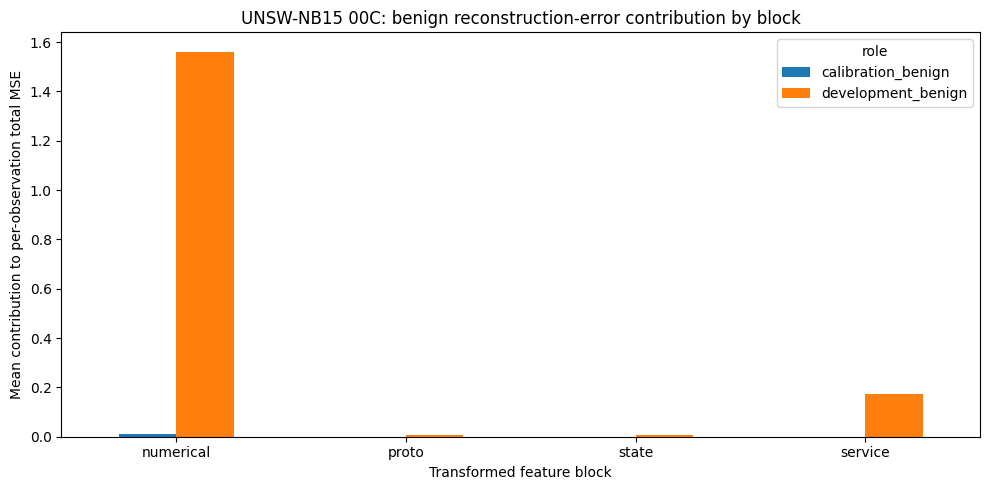

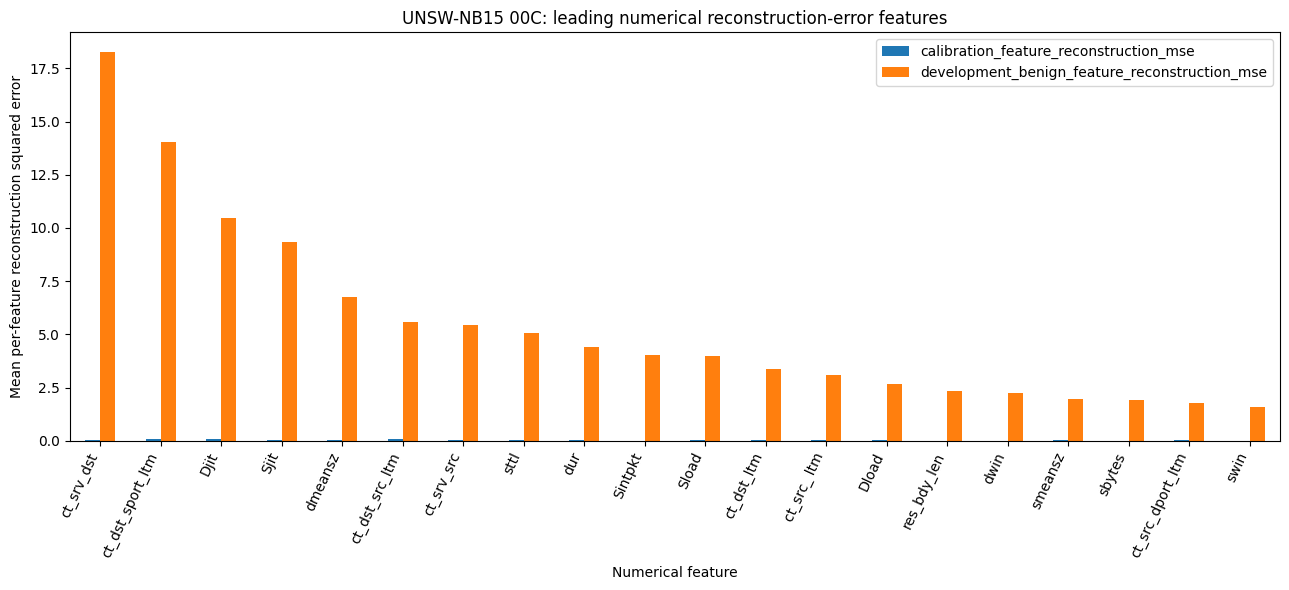


DIAGNOSTIC COMPLETE
Leading shift block: numerical
Numerical range audit ran: True
Formal Notebook 01 authorization: BLOCKED
Diagnostic root: /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_pre02_error_decomposition_diagnostic/v2_source_stratified_20260918

Please return these outputs for interpretation:
  1. /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_pre02_error_decomposition_diagnostic/v2_source_stratified_20260918/block_error_summary.csv
  2. /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_pre02_error_decomposition_diagnostic/v2_source_stratified_20260918/block_shift_attribution.csv
  3. /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_pre02_error_decomposition_diagnostic/v2_source_stratified_20260918/numerical_range_audit.csv
  4. /content/exp1v2_google_drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelli

In [14]:
# ============================================================
# 00C-4. FIGURES + DIAGNOSTIC MANIFEST — NO FORMAL AUTHORIZATION
# ============================================================
import matplotlib.pyplot as plt

# Figure 1: mean contribution to frozen total MSE by block.
fig_data = BLOCK_SUMMARY.pivot(index="block", columns="role", values="mean_total_mse_contribution").loc[BLOCK_ORDER]
ax = fig_data.plot(kind="bar", figsize=(10,5))
ax.set_ylabel("Mean contribution to per-observation total MSE")
ax.set_xlabel("Transformed feature block")
ax.set_title("UNSW-NB15 00C: benign reconstruction-error contribution by block")
plt.xticks(rotation=0)
plt.tight_layout()
fig1 = DIAGNOSTIC_ROOT / "figure_block_mean_mse_contribution.png"
plt.savefig(fig1, dpi=220, bbox_inches="tight")
plt.show()

fig2 = None
if NUMERICAL_AUDIT_RAN and len(NUMERICAL_RANGE_AUDIT):
    top = NUMERICAL_RANGE_AUDIT.head(min(20,len(NUMERICAL_RANGE_AUDIT))).copy()
    ax = top.set_index("feature")[["calibration_feature_reconstruction_mse","development_benign_feature_reconstruction_mse"]].plot(kind="bar", figsize=(13,6))
    ax.set_ylabel("Mean per-feature reconstruction squared error")
    ax.set_xlabel("Numerical feature")
    ax.set_title("UNSW-NB15 00C: leading numerical reconstruction-error features")
    plt.xticks(rotation=65, ha="right")
    plt.tight_layout()
    fig2 = DIAGNOSTIC_ROOT / "figure_top_numerical_feature_reconstruction_error.png"
    plt.savefig(fig2, dpi=220, bbox_inches="tight")
    plt.show()

caption_lines = [
    "# Diagnostic figure captions",
    "",
    "**Figure 1. Blockwise contribution to benign reconstruction error.** Mean contribution of the numerical, proto, state, and service transformed blocks to the frozen per-observation MSE anomaly score for benign threshold-calibration and development observations. Block contributions are additive by construction and were computed with the unchanged 00B smoke AE checkpoint.",
]
if fig2 is not None:
    caption_lines += ["", "**Figure 2. Numerical features contributing most strongly to reconstruction error.** Mean per-feature squared reconstruction error for calibration benign and development benign, ordered by development-benign error. This diagnostic is generated only when the numerical block is the leading contributor to the calibration-to-development shift."]
(DIAGNOSTIC_ROOT / "diagnostic_captions.md").write_text("\n".join(caption_lines)+"\n", encoding="utf-8")

manifest = {
    "dataset": DATASET_NAME,
    "protocol_version": PROTOCOL_VERSION,
    "stage": DIAGNOSTIC_STAGE_SLUG,
    "model_branch_version": MODEL_BRANCH_VERSION,
    "upstream_identity": UPSTREAM_IDENTITY,
    "source_smoke_status": SMOKE_MANIFEST.get("final_status"),
    "source_smoke_config_hash": SMOKE_CONFIG_HASH,
    "source_smoke_checkpoint_sha256": sha256_file(checkpoint_path),
    "attack_outcomes_accessed": False,
    "attack_scores_computed": False,
    "final_test_features_accessed": False,
    "final_test_outcomes_accessed": False,
    "formal_model_selection_performed": False,
    "leading_shift_block_by_absolute_mean_total_mse_contribution_increase": LEADING_BLOCK,
    "numerical_range_audit_ran": bool(NUMERICAL_AUDIT_RAN),
    "block_contribution_additivity_max_abs_error_calibration": float(cal_additivity["max_abs_difference"]),
    "block_contribution_additivity_max_relative_error_calibration": float(cal_additivity["max_relative_difference"]),
    "block_contribution_additivity_max_abs_error_development_benign": float(dev_additivity["max_abs_difference"]),
    "block_contribution_additivity_max_relative_error_development_benign": float(dev_additivity["max_relative_difference"]),
    "formal_notebook01_authorized": False,
    "next_authorized_action": "Interpret 00C diagnostic and correct/version the implicated PRE-01 or PRE-02 mechanism; rerun benign-only smoke gate before formal Notebook 01.",
    "artifacts": {
        "block_error_summary_csv": str(DIAGNOSTIC_ROOT / "block_error_summary.csv"),
        "block_shift_attribution_csv": str(DIAGNOSTIC_ROOT / "block_shift_attribution.csv"),
        "calibration_benign_rowlevel_parquet": str(DIAGNOSTIC_ROOT / "calibration_benign_block_errors.parquet"),
        "development_benign_rowlevel_parquet": str(DIAGNOSTIC_ROOT / "development_benign_block_errors.parquet"),
        "numerical_range_audit_csv": str(DIAGNOSTIC_ROOT / "numerical_range_audit.csv") if NUMERICAL_AUDIT_RAN else None,
        "numerical_retransform_consistency_csv": str(DIAGNOSTIC_ROOT / "numerical_retransform_consistency.csv") if NUMERICAL_AUDIT_RAN else None,
        "figure_block_contribution": str(fig1),
        "figure_numerical_feature_error": str(fig2) if fig2 else None,
    },
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
}
manifest["diagnostic_manifest_hash"] = sha256_bytes(canonical_json_bytes({k:v for k,v in manifest.items() if k not in {"created_at_utc","diagnostic_manifest_hash"}}))
atomic_write_json(DIAGNOSTIC_ROOT / "diagnostic_manifest.json", manifest)

print("\nDIAGNOSTIC COMPLETE")
print("Leading shift block:", LEADING_BLOCK)
print("Numerical range audit ran:", NUMERICAL_AUDIT_RAN)
print("Formal Notebook 01 authorization: BLOCKED")
print("Diagnostic root:", DIAGNOSTIC_ROOT)
print("\nPlease return these outputs for interpretation:")
print("  1.", DIAGNOSTIC_ROOT / "block_error_summary.csv")
print("  2.", DIAGNOSTIC_ROOT / "block_shift_attribution.csv")
if NUMERICAL_AUDIT_RAN:
    print("  3.", DIAGNOSTIC_ROOT / "numerical_range_audit.csv")
    print("  4.", DIAGNOSTIC_ROOT / "numerical_retransform_consistency.csv")
